### Importing all required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import datetime as dt
import calendar,warnings,itertools,matplotlib,keras,shutil
import tensorflow as tf
import statsmodels.api as sm
from datetime import datetime
from sklearn.model_selection import train_test_split,cross_val_score, cross_val_predict
from sklearn import svm,metrics,tree,preprocessing,linear_model
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge,LinearRegression,LogisticRegression,ElasticNet, Lasso
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier, GradientBoostingRegressor,BaggingClassifier,ExtraTreesClassifier
from sklearn.metrics import accuracy_score,mean_squared_error,recall_score,confusion_matrix,f1_score,roc_curve, auc
from sklearn.datasets import load_iris,make_regression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.kernel_ridge import KernelRidge
from keras import Sequential
from keras.layers import Dense
from IPython.core import display as ICD
#from tensorflow_core.estimator import inputs

#Hiding the warnings
warnings.filterwarnings('ignore') 


In [2]:
dataset = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    header=0,
    encoding="unicode_escape"
)

dataset.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


# Data Cleaning

In [3]:
dataset.shape

(180519, 53)

The total data set consists of 180519 records and 53 columns

In [4]:
dataset.apply(lambda x: sum(x.isnull())) #Checking missing values

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


The data consists of some missing values from Customer Lname, Product Description, Order Zipcode and, Customer Zipcode which should be removed or replaced before proceeding with the analysis. And also, since there is a chance different customers might have the same first name or same last name a new column with ‘customer full name’ is created to avoid any ambiguities.

In [5]:
# Adding first name and last name together to create new column
dataset['Customer Full Name'] = dataset['Customer Fname'].astype(str)+dataset['Customer Lname'].astype(str)

To make it easier for analysis some unimportant columns are dropped

In [6]:
data=dataset.drop(['Customer Email','Product Status','Customer Password','Customer Street','Customer Fname','Customer Lname',
           'Latitude','Longitude','Product Description','Product Image','Order Zipcode','shipping date (DateOrders)'],axis=1)
data.shape

(180519, 42)


There are 3 missing values in Customer Zipcode column. Since the missing values are just zip codes which are not very important these are replaced with zero before proceeding with data analysis.

In [7]:
data['Customer Zipcode']=data['Customer Zipcode'].fillna(0)#Filling NaN columns with zero

# Data Visualisation

To find important parameters, data correlation is performed.

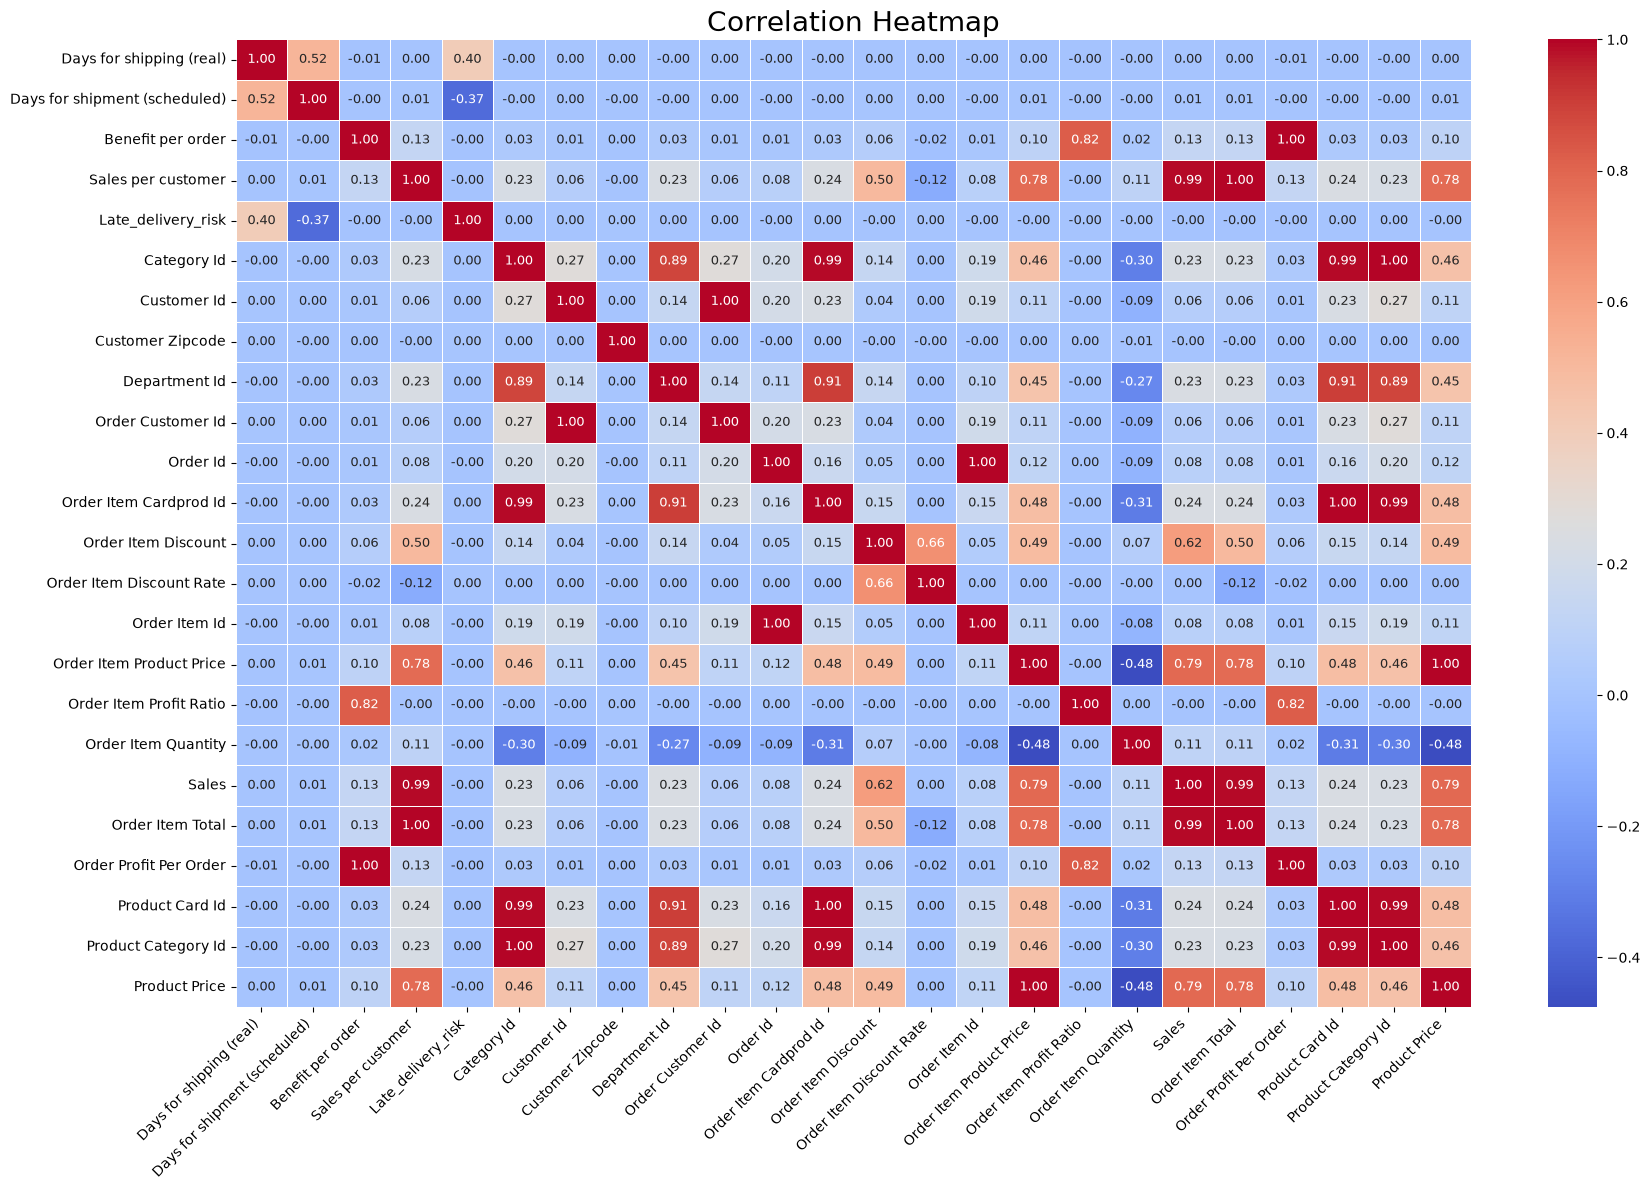

In [8]:
plt.figure(figsize=(18, 12))

sns.heatmap(
    data.select_dtypes(include='number').corr(),
    annot=True,
    linewidths=0.5,
    fmt='.2f',
    cmap='coolwarm',
    annot_kws={"size": 9}
)

plt.title("Correlation Heatmap", fontsize=20)
plt.xticks(fontsize=10, rotation=45, ha='right')
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

We can observe that product price price has high correlation with Sales,Order Item Total.

As the data which is being used for analysis is related to Supply chain, it makes sense to find which region has most sales? It can be found by using groupby method which will segregate similar market regions together and add all sales for that particular region using 'sum' function.

<Axes: title={'center': 'Total sales for all regions'}, xlabel='Order Region'>

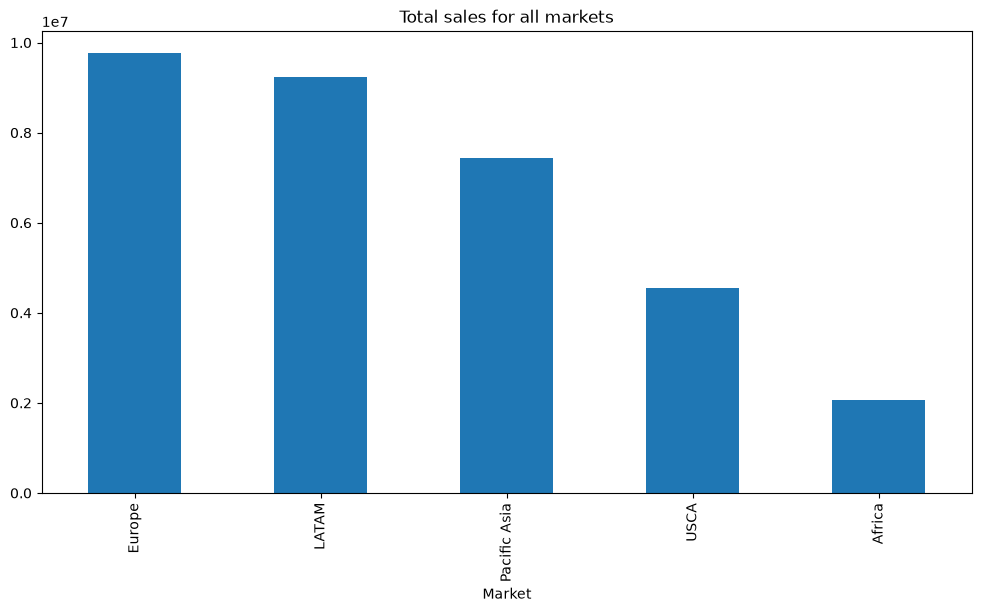

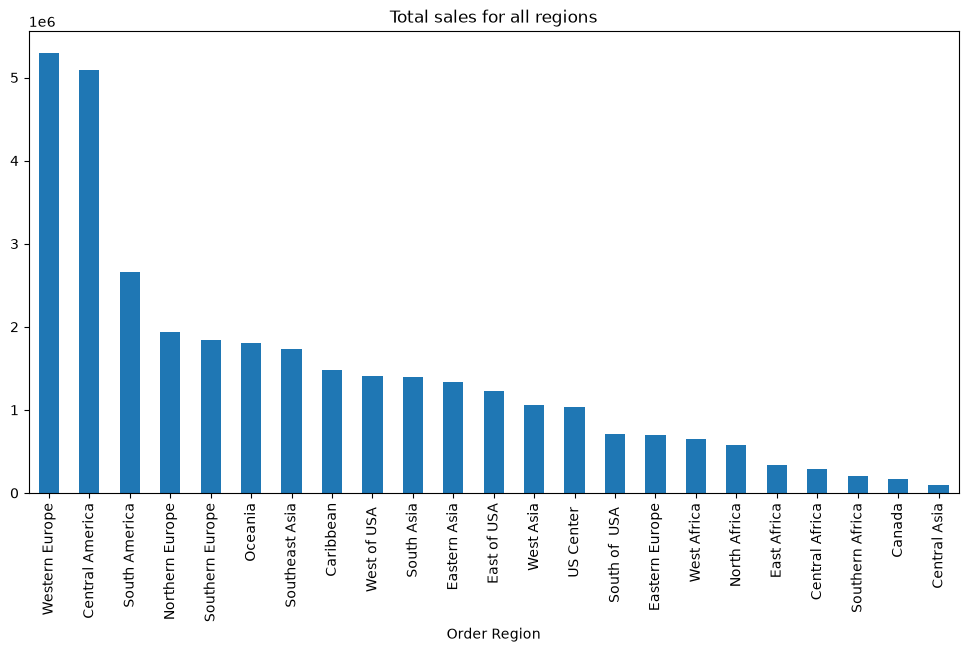

In [9]:
market = data.groupby('Market') #Grouping by market
region = data.groupby('Order Region')
plt.figure(1)
market['Sales per customer'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales for all markets")
plt.figure(2)
region['Sales per customer'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales for all regions")

It could be seen from the graph that European market has the most number of sales whereas Africa has the least.In these markets western europe regions and central america recorded highest sales. 

Which catergory of products has highest sales?The same method can be followed here to see the product category with highest sales

<Axes: title={'center': 'Average price'}, xlabel='Category Name'>

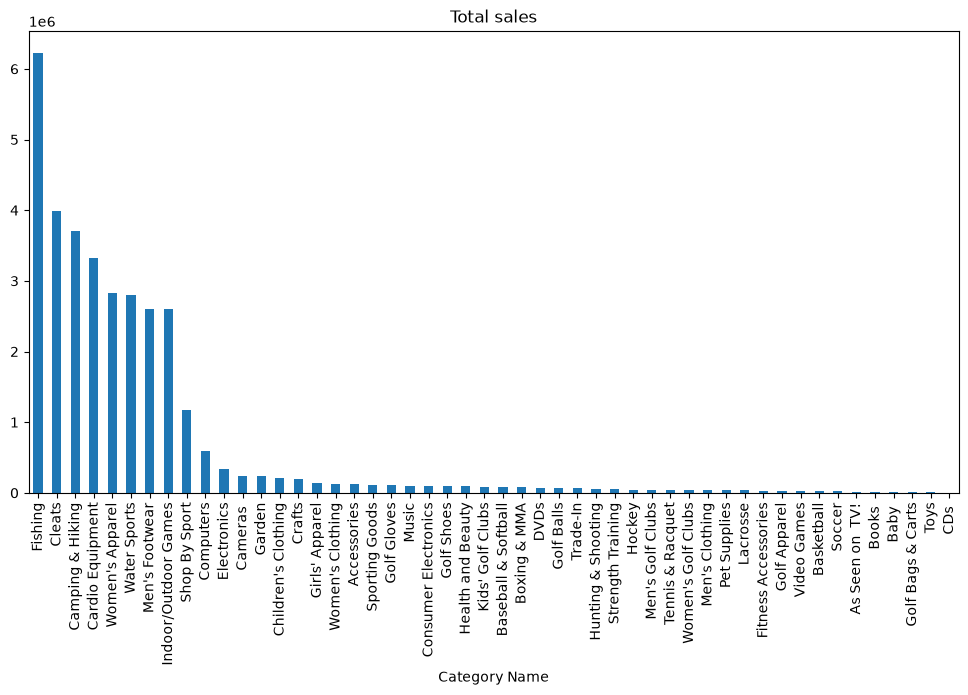

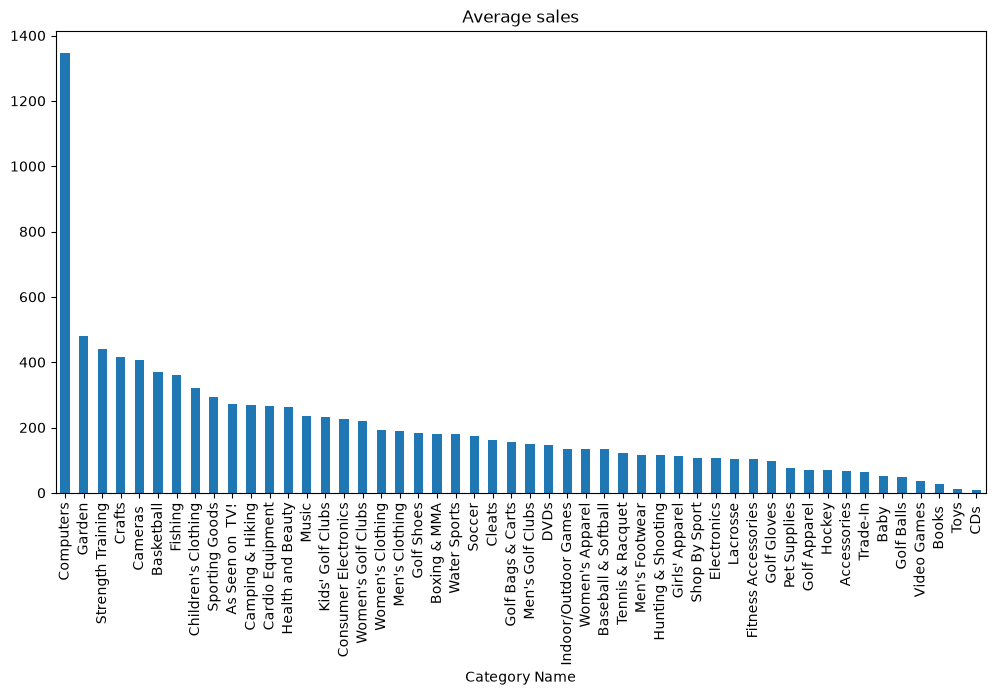

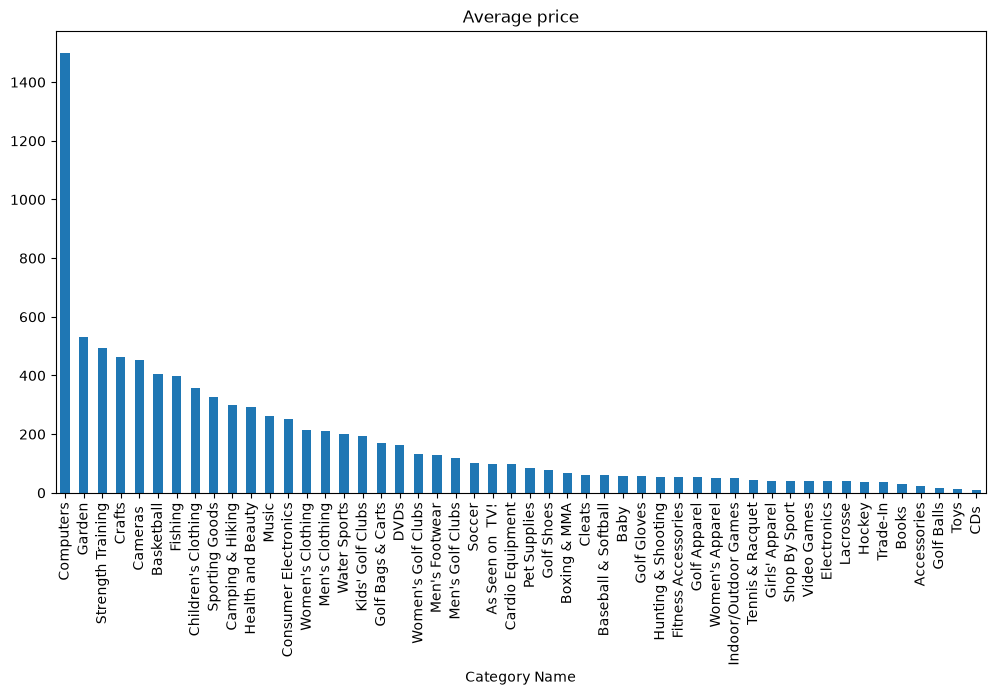

In [10]:
#Grouping all categories
cat = data.groupby('Category Name')
plt.figure(1)
# Total sum of sales for all categories
cat['Sales per customer'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales")
# Mean sales for all categories
plt.figure(2)
cat['Sales per customer'].mean().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Average sales")
plt.figure(3)
# Mean prices for all categories
cat['Product Price'].mean().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Average price")

As we can see from fig 1 that the fishing category had most number of sales followed by the Cleats.However it is suprising to see that top 7 products with highest price on average are the most sold products on average with computers having almost 1350 sales despite price being 1500$. Since correlation was high between Price and Sales it will be intresting to see how price is impacting the sales for all the products to see the trend.

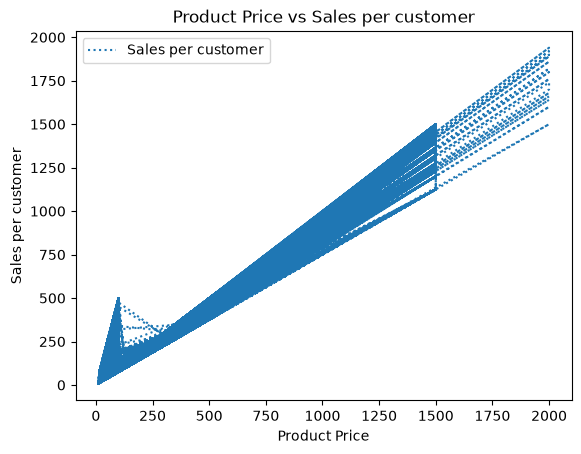

In [11]:
data.plot(x='Product Price', y='Sales per customer',linestyle='dotted',
     markerfacecolor='blue', markersize=12) 
plt.title('Product Price vs Sales per customer')#title
plt.xlabel('Product Price')  # X-axis title
plt.ylabel('Sales per customer') # Y=axis title
plt.show()

It can be observed that prices has linear relation with sales. Which quarter recorded highest sales? It can be found  by dividing order time into years,months,week day,hour to better observe the trend.

In [12]:

# Convert order date to datetime format
data['order date (DateOrders)'] = pd.to_datetime(
    data['order date (DateOrders)']
)

# Extract date information
data['order_year'] = data['order date (DateOrders)'].dt.year

data['order_month'] = data['order date (DateOrders)'].dt.month

data['order_week_day'] = data['order date (DateOrders)'].dt.day_name()

data['order_hour'] = data['order date (DateOrders)'].dt.hour

data['order_month_year'] = data['order date (DateOrders)'].dt.to_period('M')

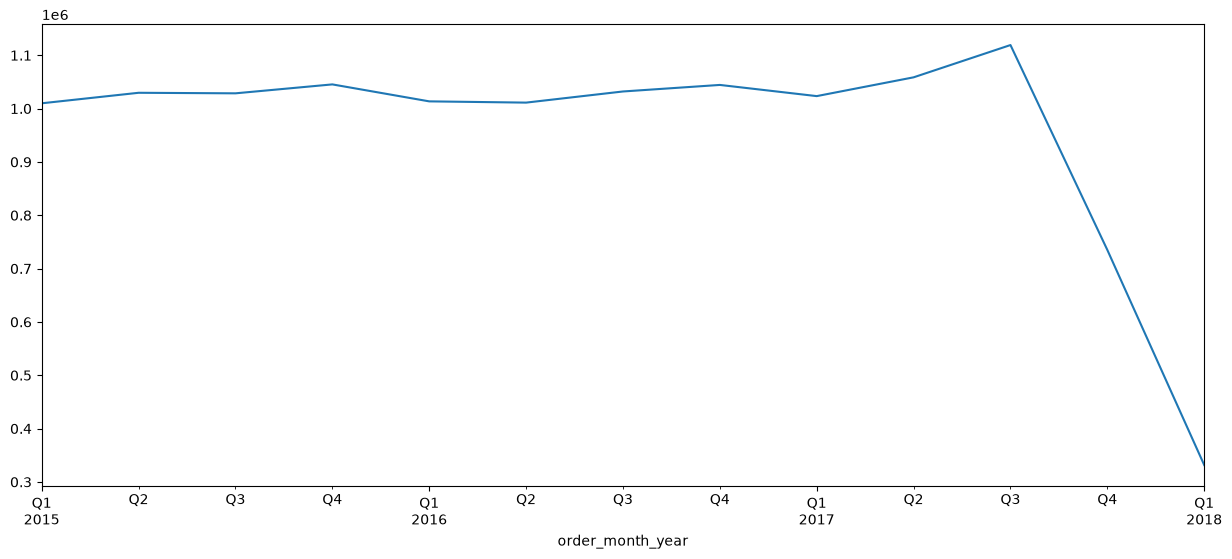

In [13]:
quater= data.groupby('order_month_year')
quartersales=quater['Sales'].sum().resample('Q').mean().plot(figsize=(15,6))

By seeing above graph it can be seen that sales are consistent from Q1 2015 until Q3 of 2017 and suddenly dipped by Q1 2018. What is the purchase trend in week days,hours and months?

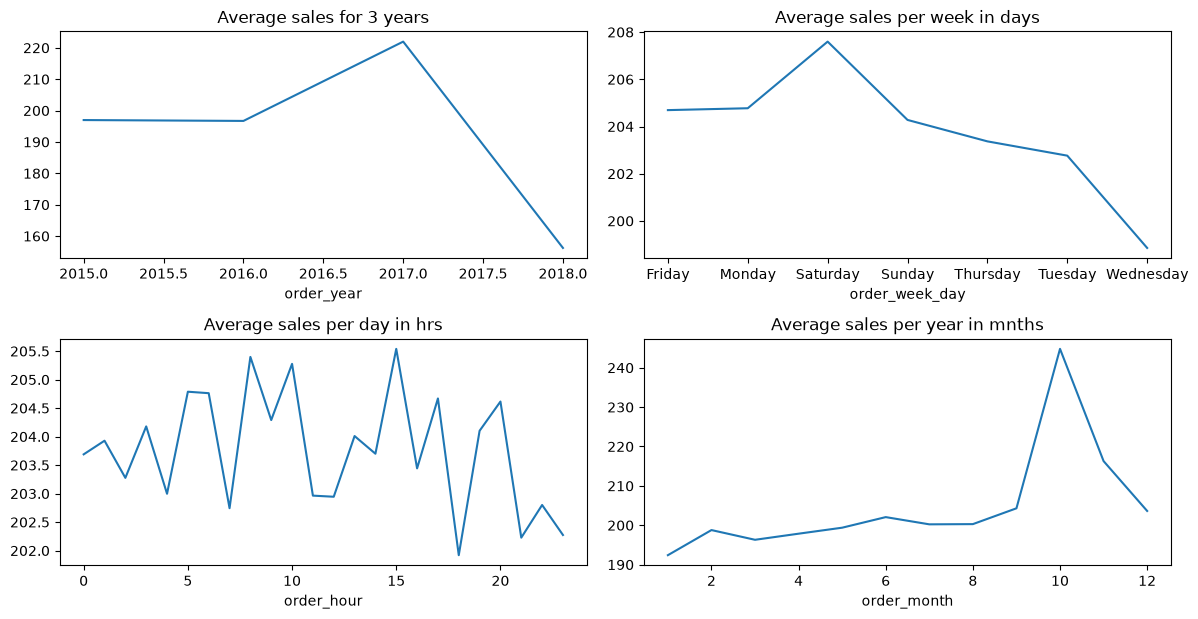

In [14]:
plt.figure(figsize=(10,12))
plt.subplot(4, 2, 1)
quater= data.groupby('order_year')
quater['Sales'].mean().plot(figsize=(12,12),title='Average sales for 3 years')
plt.subplot(4, 2, 2)
days=data.groupby("order_week_day")
days['Sales'].mean().plot(figsize=(12,12),title='Average sales per week in days')
plt.subplot(4, 2, 3)
hrs=data.groupby("order_hour")
hrs['Sales'].mean().plot(figsize=(12,12),title='Average sales per day in hrs')
plt.subplot(4, 2, 4)
mnth=data.groupby("order_month")
mnth['Sales'].mean().plot(figsize=(12,12),title='Average sales per year in mnths')
plt.tight_layout()
plt.show()

How price is impacting sales, when and which products are having more sales are found.The most number of orders came in October followed by November, and orders for all other months are consistent.Highest number of orders are placed by customers in 2017. 
Saturday recorded highest number of average sales and wednesday with the least number of sales. The average sales are consistent throughout the day irrespective of time with std of 3.

It is also important to know what type of payment method is being preferred by people to buy all these products in all regions? It can be found using .unique() method to see different payment methods.

In [15]:
data['Type'].unique()

<StringArray>
['DEBIT', 'TRANSFER', 'CASH', 'PAYMENT']
Length: 4, dtype: str

It is found that four types of payment methods are used.Which payment method is preferred the most by people in different regions?

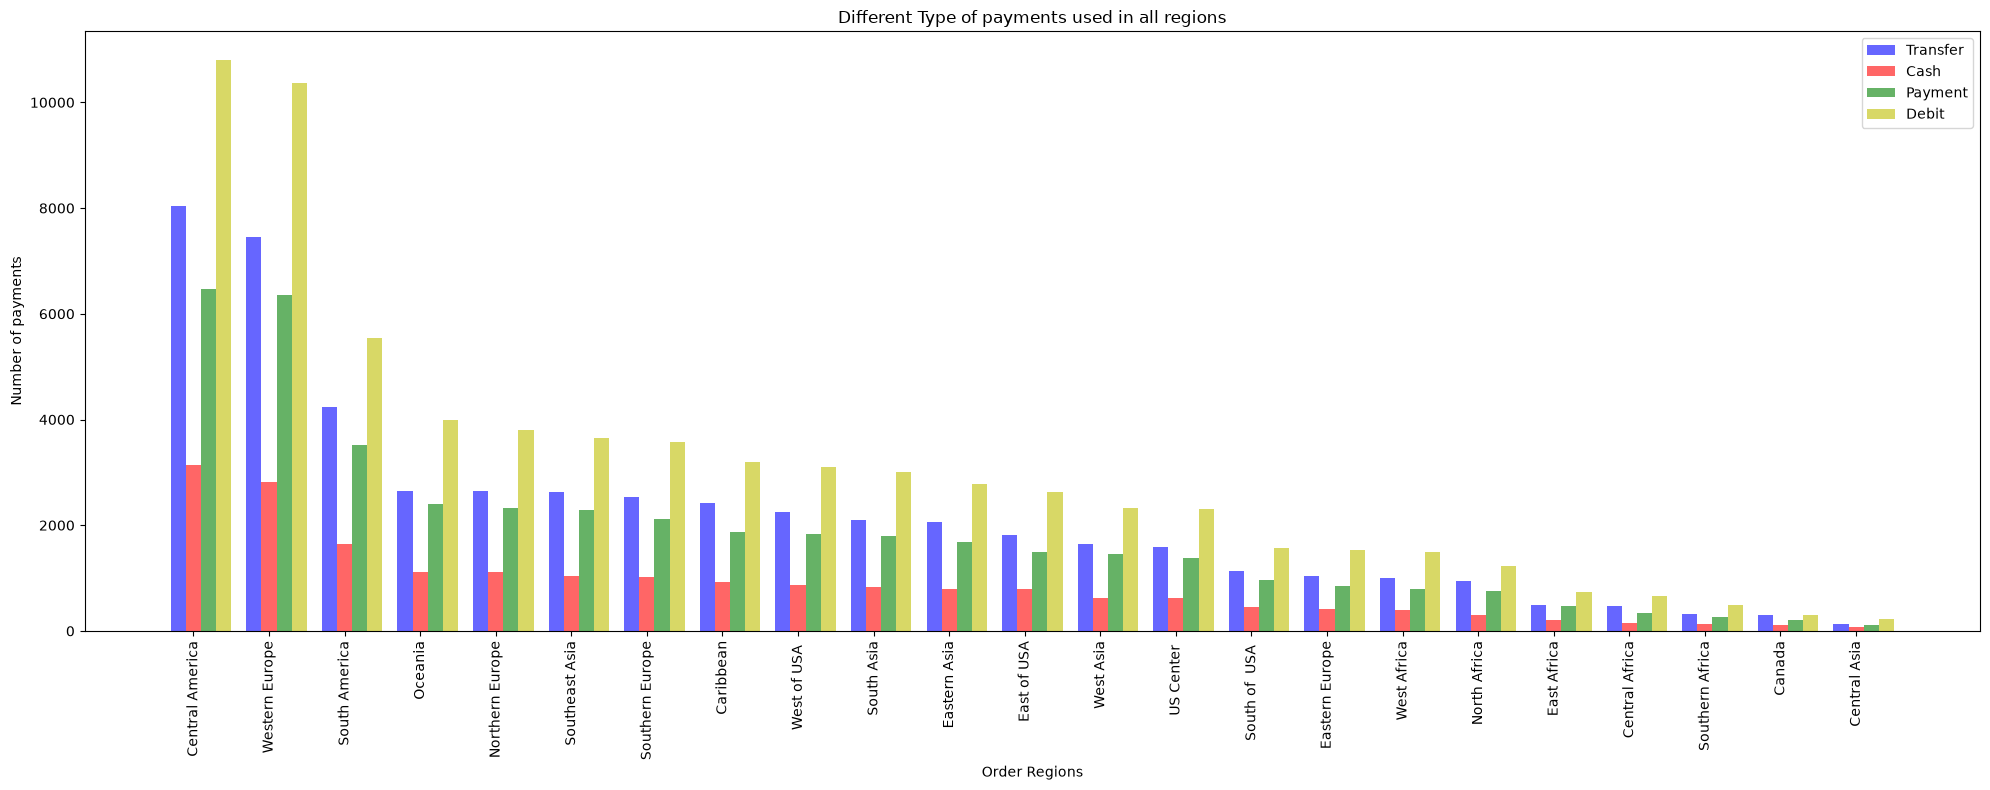

In [16]:
#xyz = data.groupby('Type')
xyz1 = data[(data['Type'] == 'TRANSFER')]
xyz2= data[(data['Type'] == 'CASH')]
xyz3= data[(data['Type'] == 'PAYMENT')]
xyz4= data[(data['Type'] == 'DEBIT')]
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
count3=xyz3['Order Region'].value_counts()
count4=xyz4['Order Region'].value_counts()
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8))
index=np.arange(n_groups)
bar_width=0.2
opacity=0.6
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='b',label='Transfer')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='r',label='Cash')
type3=plt.bar(index+bar_width+bar_width,count3,bar_width,alpha=opacity,color='g',label='Payment')
type4=plt.bar(index+bar_width+bar_width+bar_width,count4,bar_width,alpha=opacity,color='y',label='Debit')
plt.xlabel('Order Regions')
plt.ylabel('Number of payments')
plt.title('Different Type of payments used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()


Debit type is most preferred payment method by people in all regions, Cash payment being the least preferred method.

Some products are having negative benefit per orders which indicates that the orders are generating loss of revenue to the company. Which products are these?

Total revenue lost with orders -3883547.345768667


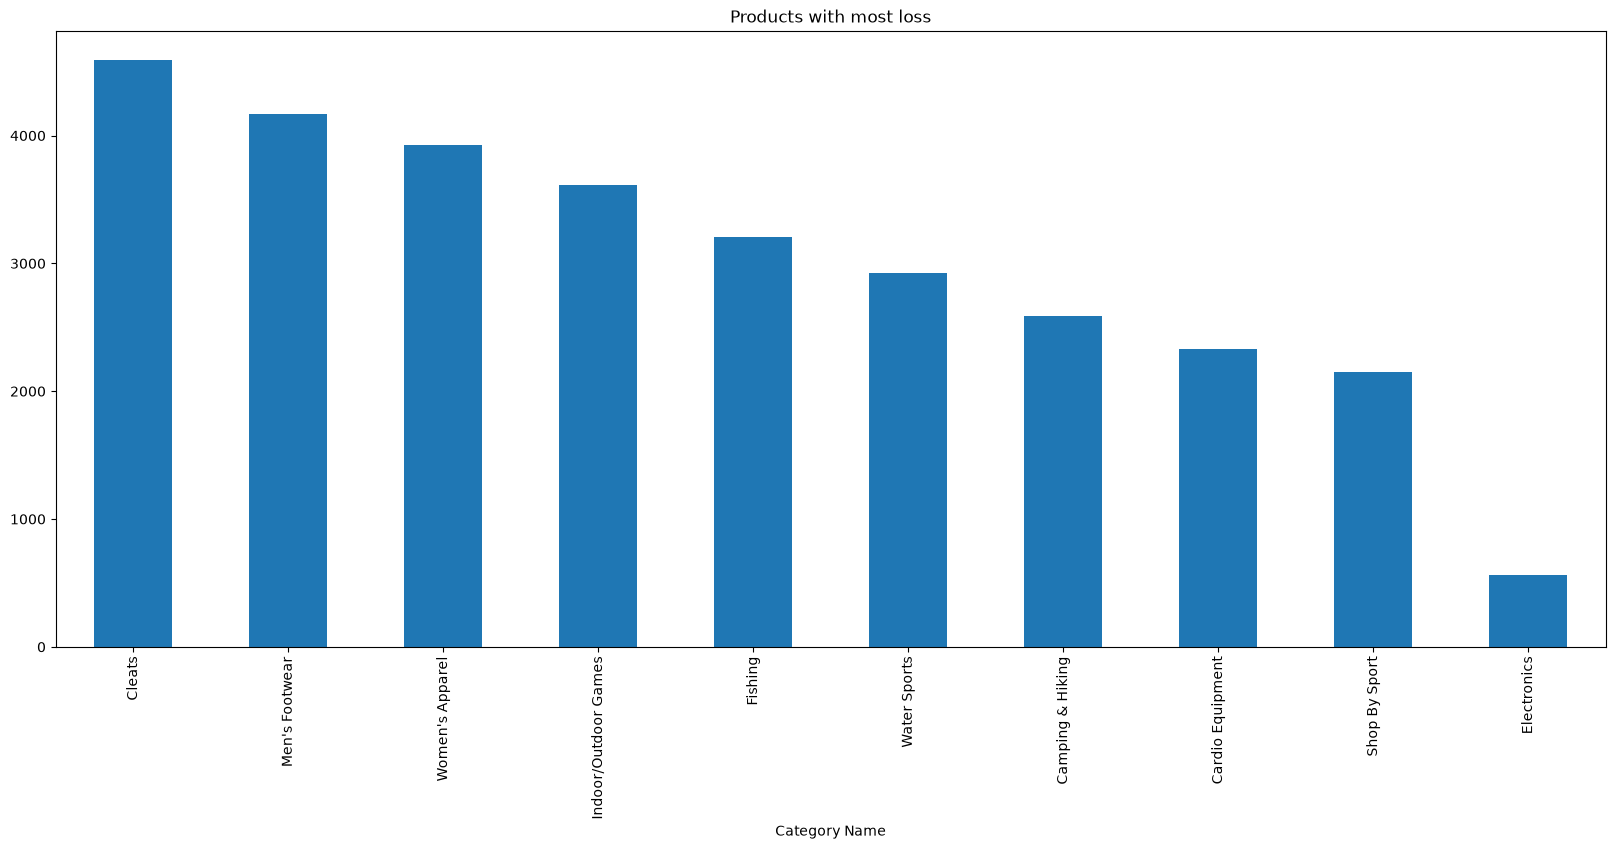

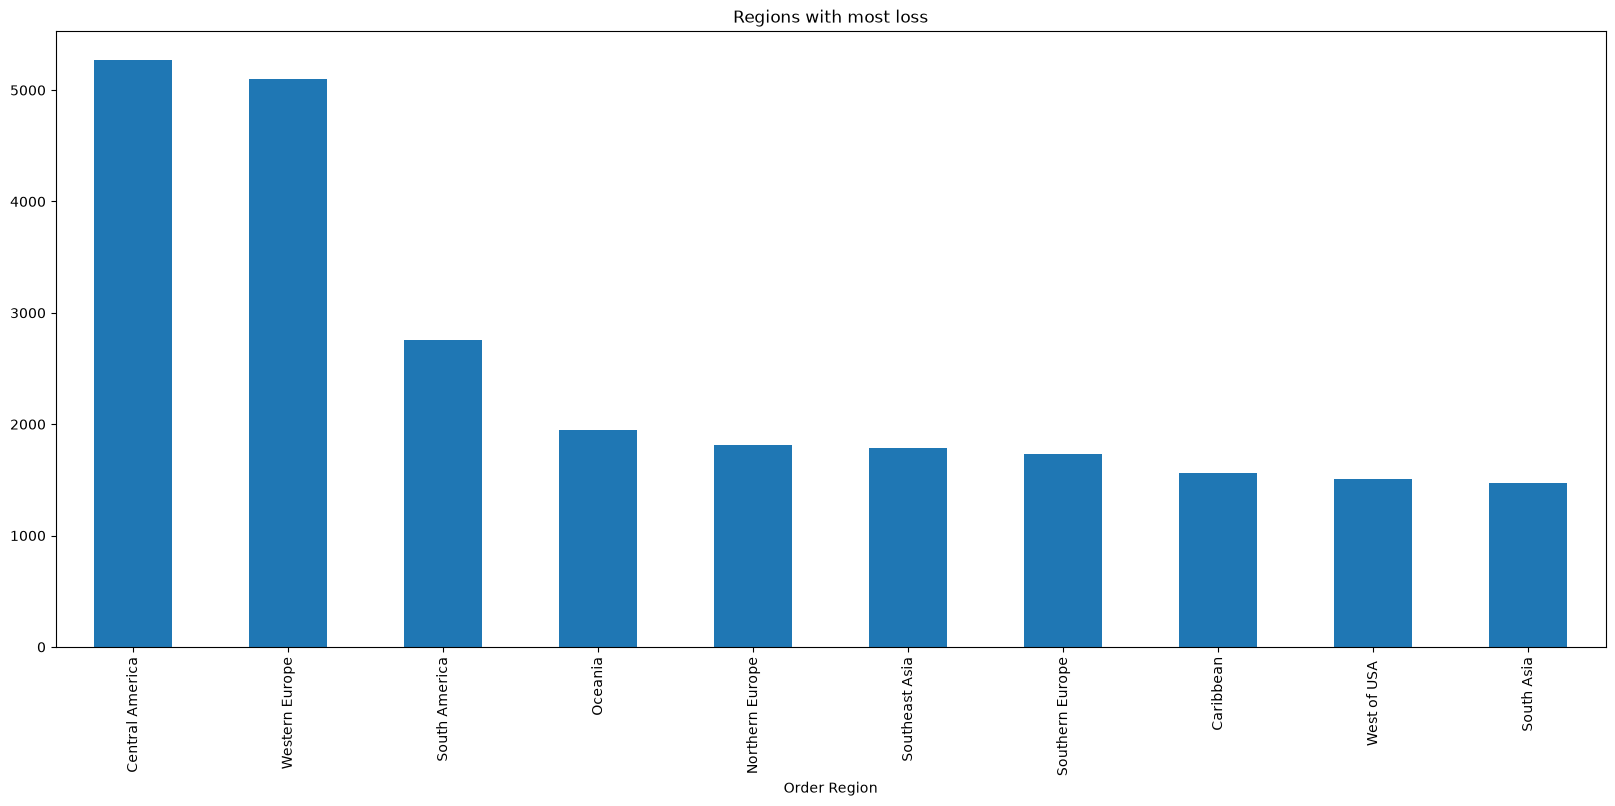

In [17]:
loss = data[(data['Benefit per order']<0)]
#Plotting top 10 products with most loss
plt.figure(1)
loss['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Products with most loss")
plt.figure(2)
loss['Order Region'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Regions with most loss")
#Sum of total sales which are lost
print('Total revenue lost with orders',loss['Benefit per order'].sum())

The total loss sales are approximately 3.9 Millions which is an huge amount.It can be seen that Cleats is the category with most loss sales followed by Mens footwear.Most lost sales are happeing in central america and western europe region.This lost sales may have happened due to suspected frauds or late deliveries.

Finding which payment method is used to conduct frauds can be useful to  prevent fraud from happening in future

In [18]:
#Checking type of payment used to conduct fraud other than Transfer
xyz = data[(data['Type'] != 'TRANSFER')&(data['Order Status'] == 'SUSPECTED_FRAUD')]
xyz['Order Region'].value_counts()

Series([], Name: count, dtype: int64)

It can be clearly seen that there are no frauds conducted with DEBIT,CASH,PAYMENT methods so all the suspected fraud orders are made using wire transfer probably from abroad. Which region and what product is being suspected to the fraud the most? 

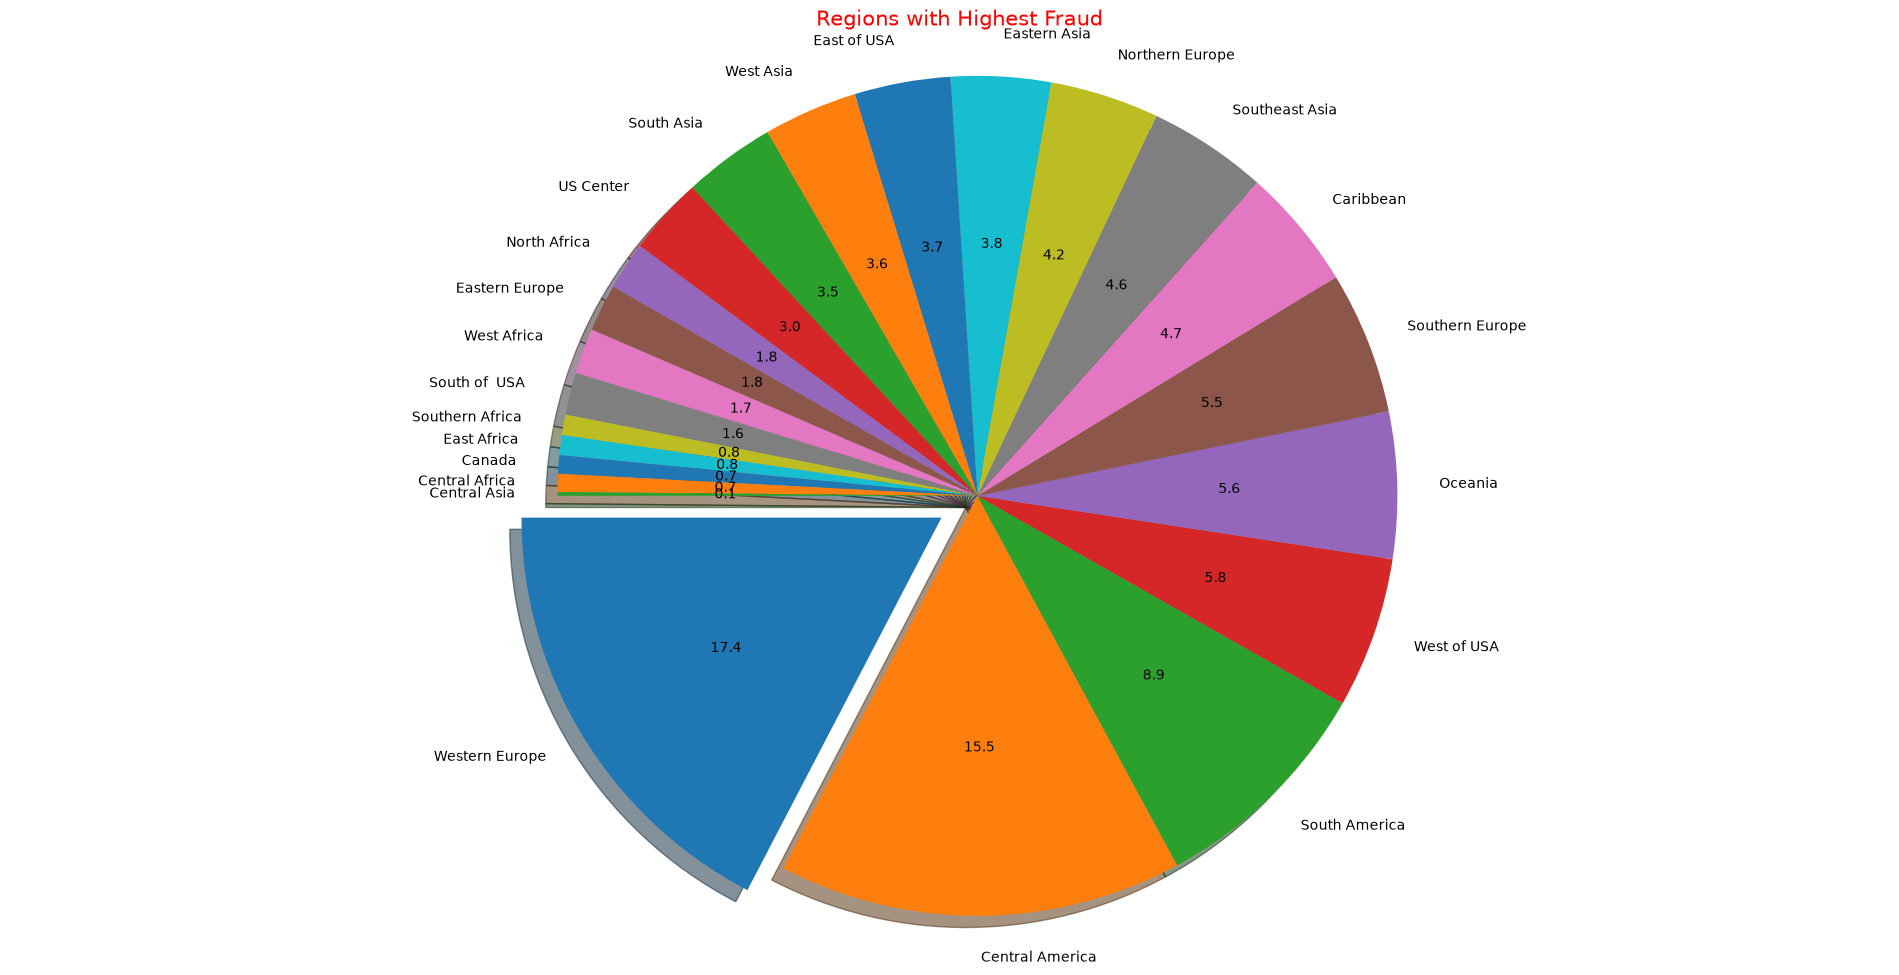

In [19]:
high_fraud = data[(data['Order Status'] == 'SUSPECTED_FRAUD') & (data['Type'] == 'TRANSFER')]#separating orders with suspected fraud
#Plotting pie chart with respect to order region
fraud=high_fraud['Order Region'].value_counts().plot.pie(figsize=(24,12),
                                                  startangle=180, explode=(0.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0),autopct='%.1f',shadow=True,)
plt.title("Regions with Highest Fraud",size=15,color='r') # Plotting title
plt.ylabel(" ")
fraud.axis('equal') 
plt.show()

It can be observed that highest number of suspected fraud orders are from Western Europe which is approximately 17.4% of total orders followed by Central America with 15.5%. Which product is being suspected fraud the most?

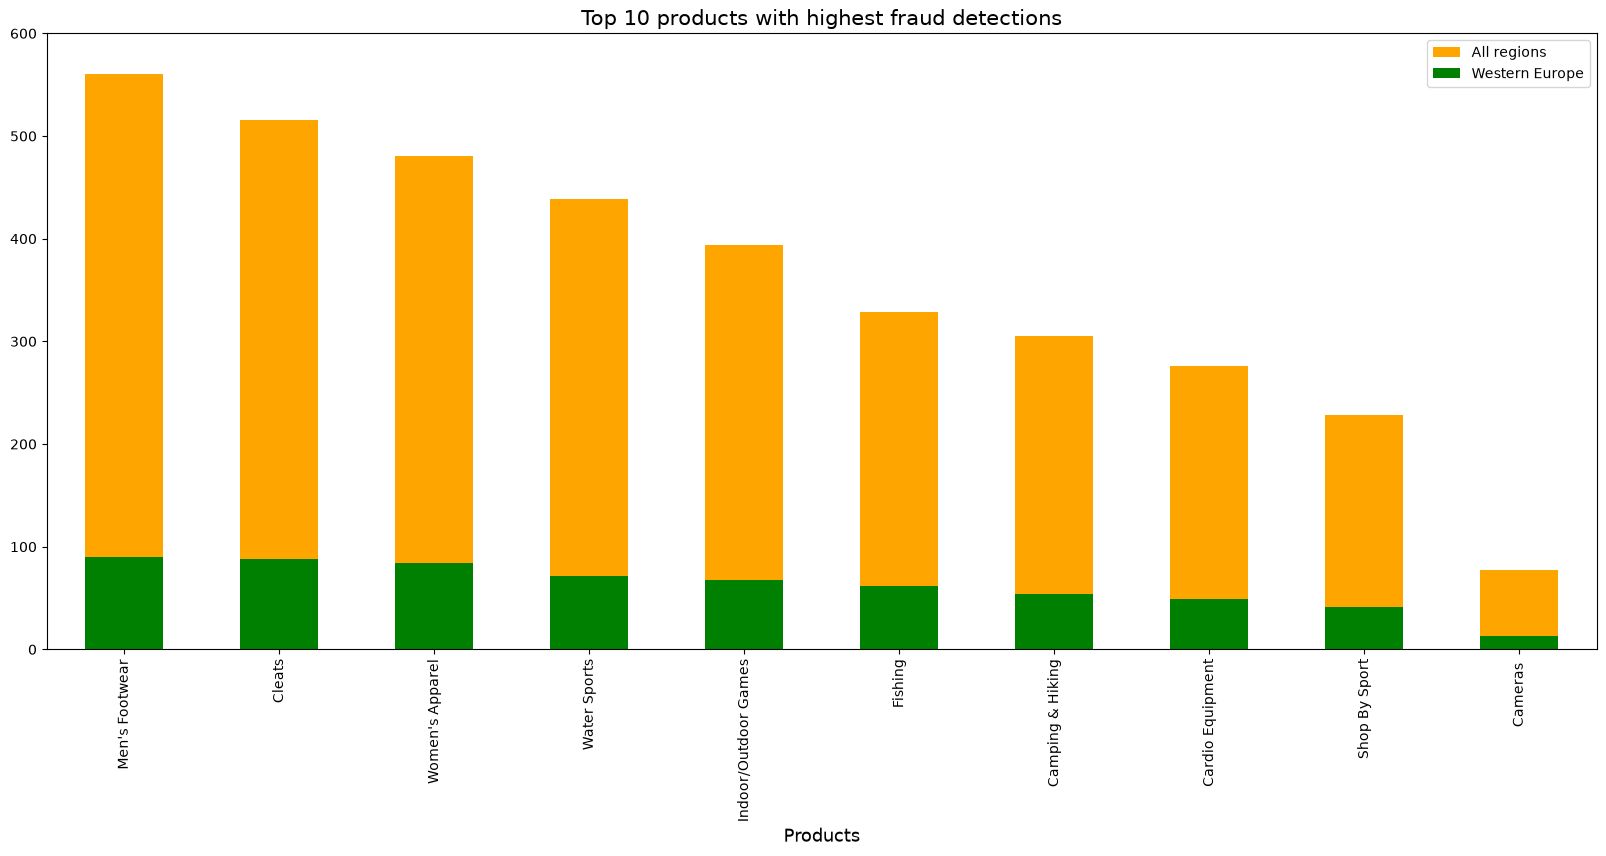

In [20]:
high_fraud1 = data[(data['Order Status'] == 'SUSPECTED_FRAUD')] # 
high_fraud2 = data[(data['Order Status'] == 'SUSPECTED_FRAUD') &(data['Order Region'] == 'Western Europe')]
#Plotting bar chart for top 10 most suspected fraud department in all regions
fraud1=high_fraud1['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Fraud Category",color='orange')
#Plotting bar chart for top 10 most suspected fraud department in Western Europe
fraud2=high_fraud2['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Fraud product in Western Europe",color='green')
plt.legend(["All regions", "Western Europe"])
plt.title("Top 10 products with highest fraud detections", size=15)
plt.xlabel("Products", size=13)
plt.ylim(0,600)
plt.show()

It is very suprising to see that cleats department is being suspected to fraud the most followed by Men's footwear in all the regions and also in Western Europe.Which customers are conducting all these fraud?

<Axes: title={'center': 'Top 10 Highest Fraud Customers'}, xlabel='Customer Full Name'>

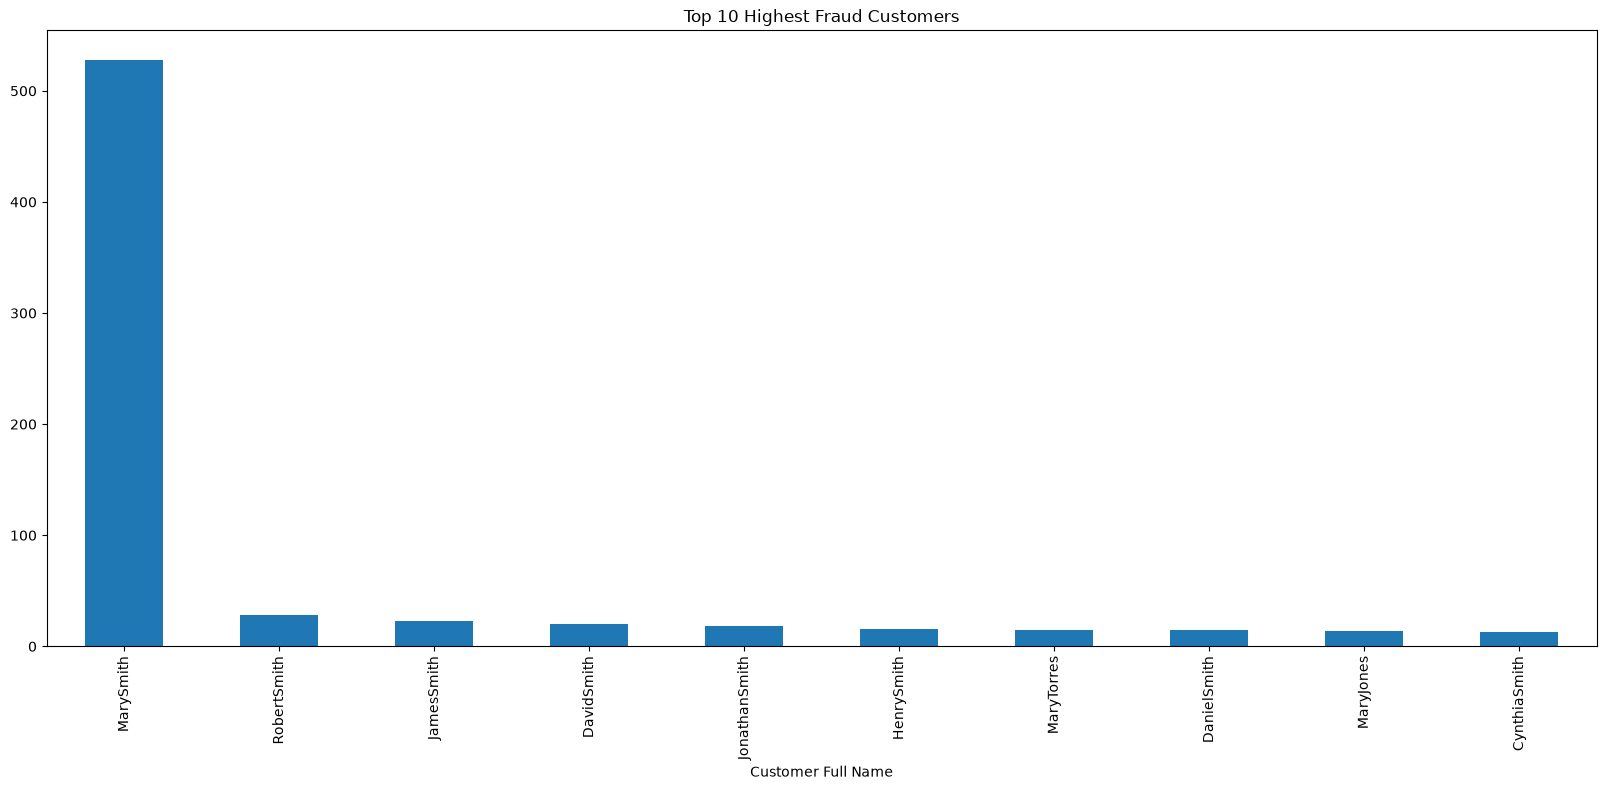

In [21]:
#Filtering out suspected fruad orders
cus = data[(data['Order Status'] == 'SUSPECTED_FRAUD')] 
#Top 10 customers with most fraud
cus['Customer Full Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Top 10 Highest Fraud Customers")

The customer named Mary Smith alone was responible for trying to conduct fraud 528 times which is very shocking .How  much amount exactly did she conduct fraud orders?

In [22]:
#Filtering orders of mary smith with suspected fraud
amount = data[(data['Customer Full Name'] == 'MarySmith')&(data['Order Status'] == 'SUSPECTED_FRAUD')]
#Plotting bar chart for top 10 most suspected fraud customers
amount['Sales'].sum()

np.float64(102491.66191043999)

The total amount was almost 102k which is very huge amount.Since Mary was using different address every time when placing orders, a new customer id was issued each time which makes it difficult to identify the customer and ban them. All these parameters should be taken into consideration to improve fraud detection algorithm so fraud can be identified more accurately.

Delivering products to customer on time without late delivery is another important aspect for a supply chain company because customers will not be satisfied if products are not delivered on time. What  category of products are being delivered late the most?

<Axes: title={'center': 'Top 10 products with most late deliveries'}, xlabel='Category Name'>

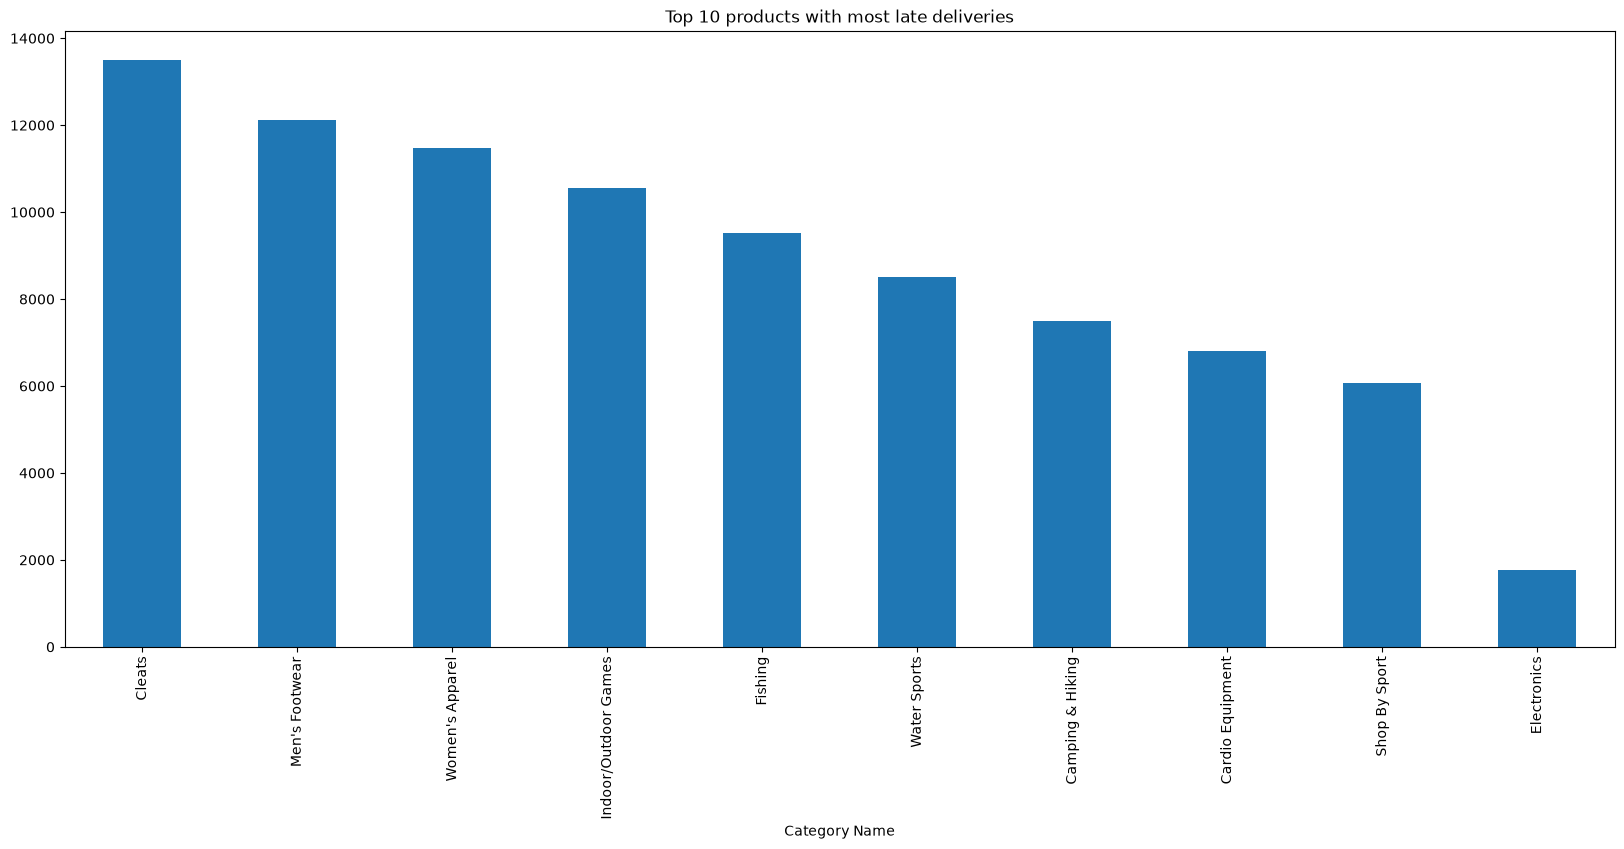

In [23]:
#Filtering columns with late delivery status
late_delivery = data[(data['Delivery Status'] == 'Late delivery')]
#Top 10 products with most late deliveries
late_delivery['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Top 10 products with most late deliveries")


It can be seen that orders with Cleats department is getting delayed the most followed by Men's Footwear.For some orders risk of late delivery is given in data.The products with late delivery risk are compared with late delivered products. 

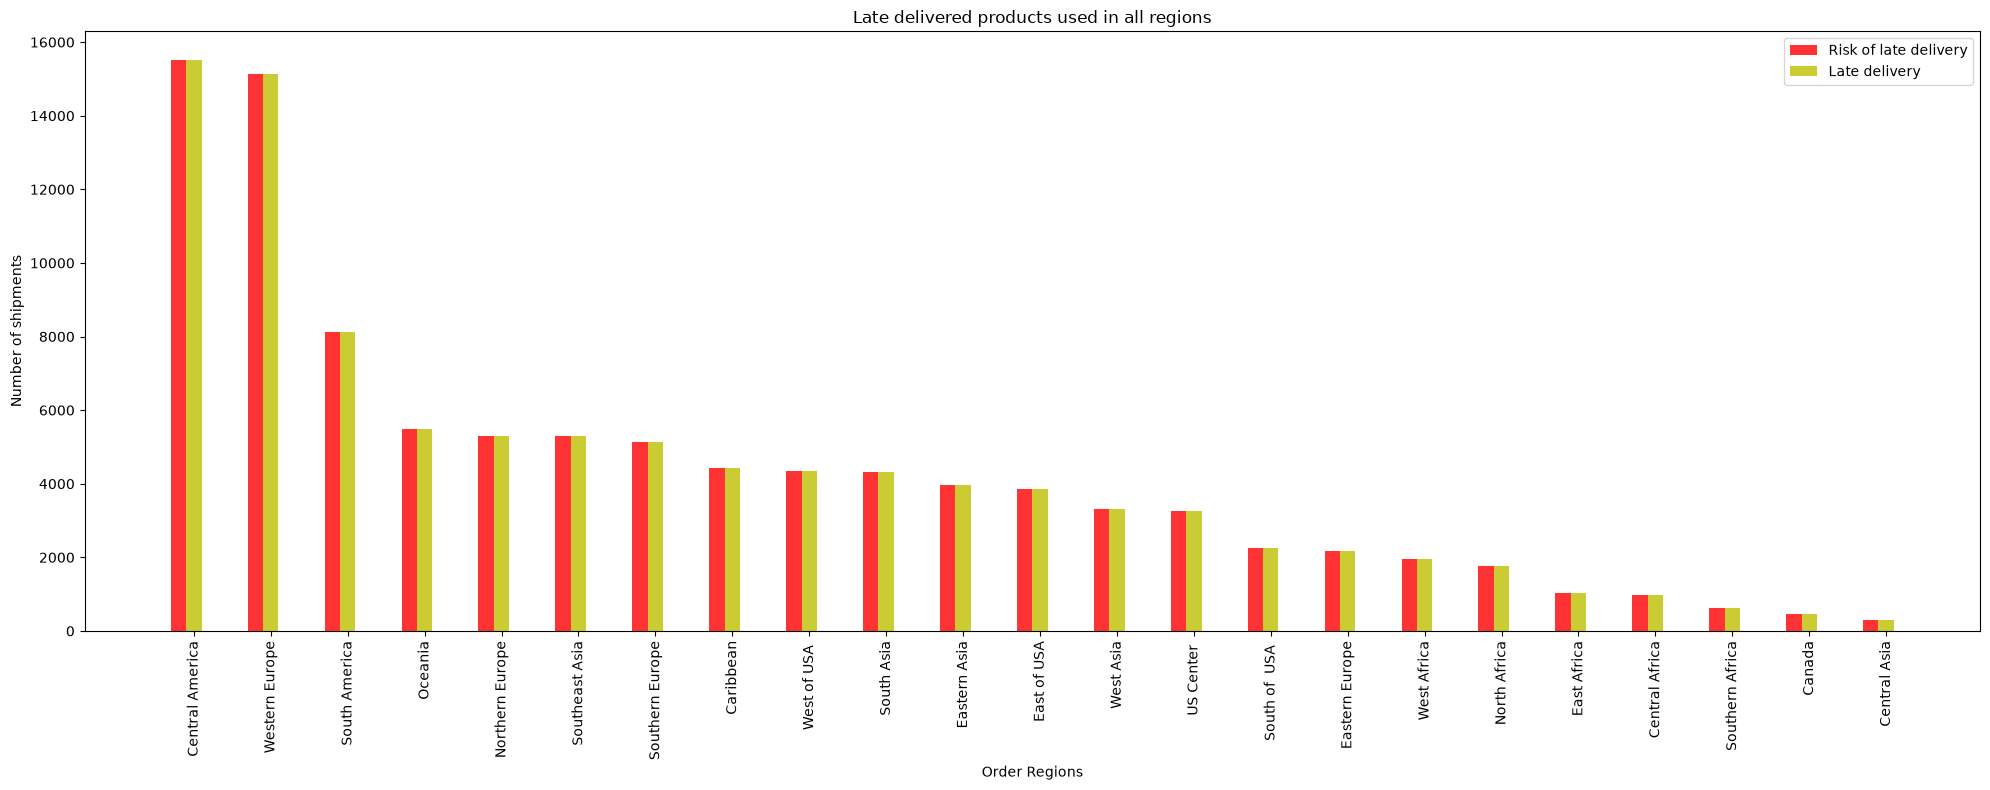

In [24]:
#Filtering orders with late delivery risk
xyz1 = data[(data['Late_delivery_risk'] == 1)]
#Filtering late delivered orders
xyz2 = data[(data['Delivery Status'] == 'Late delivery')]
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
#Index names
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8)) #Figure size
index=np.arange(n_groups)
bar_width=0.2
opacity=0.8
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='r',label='Risk of late delivery')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='y',label='Late delivery')
plt.xlabel('Order Regions')
plt.ylabel('Number of shipments')
plt.title('Late delivered products used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()


Thus,it can be concluded that for all the products with late delivery risk irrespective of region the product is actually being delivered late,to avoid late delivery the company can ship products faster using better shipping method or schedule more time of Days for shipment so customers will know in advance when the products will reach them. It will be interesting to see the number of late deliveried orders for different types of shipment method in all regions.

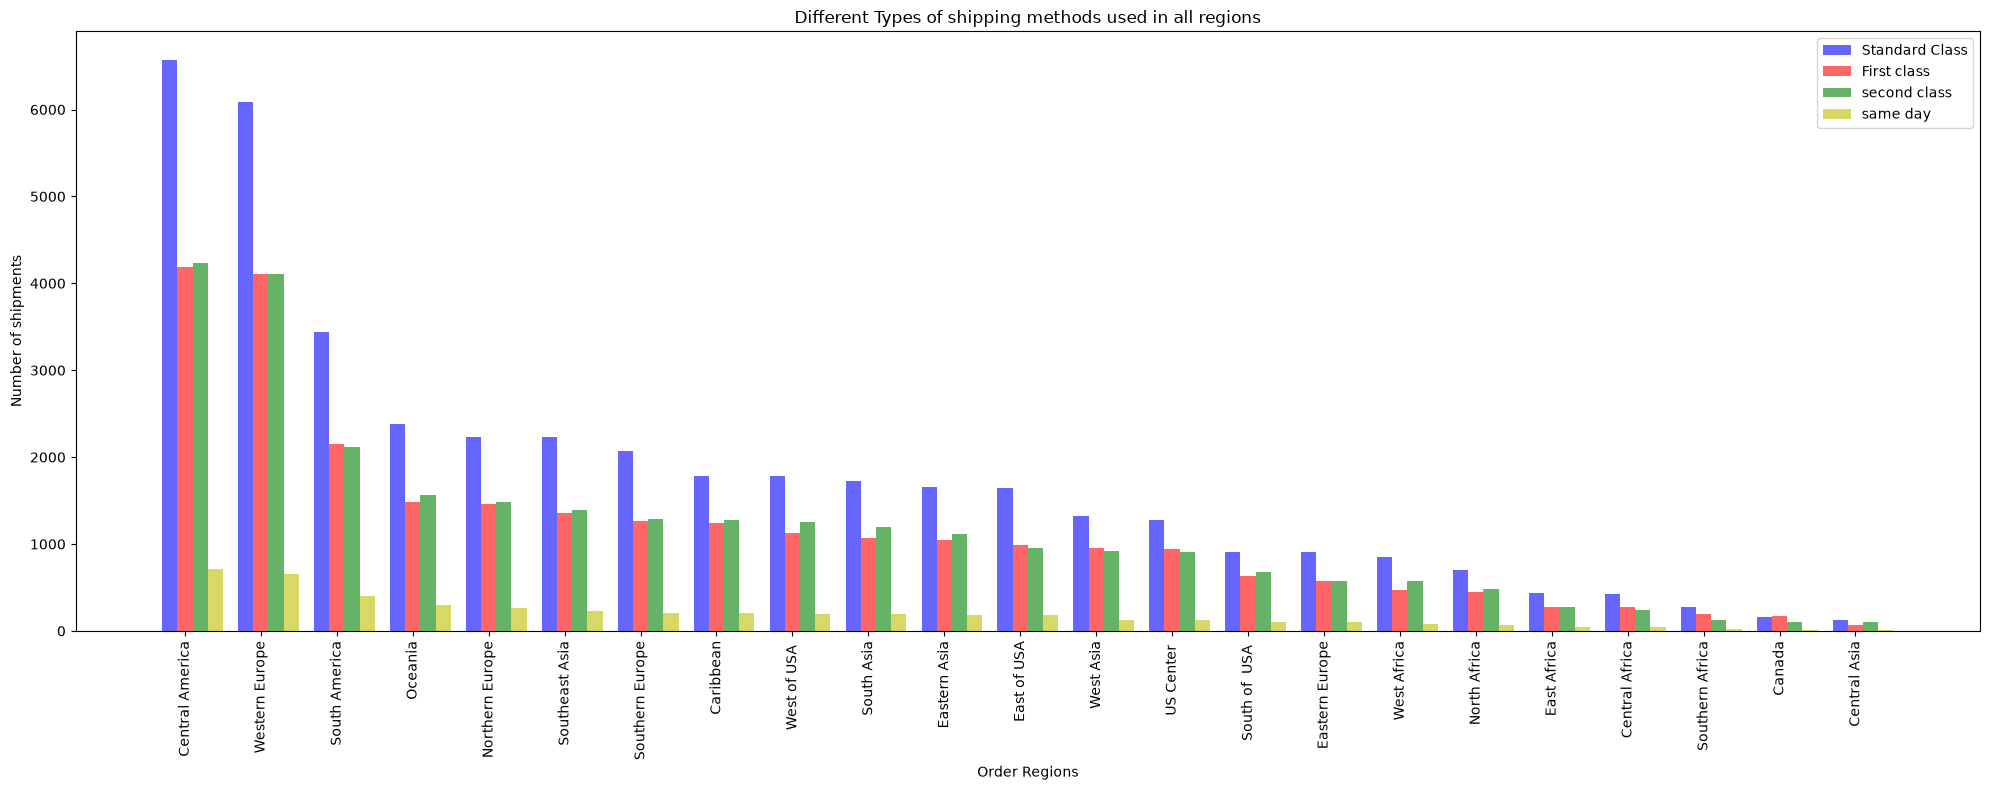

In [25]:
#Filtering late delivery orders with standard class shipping
xyz1 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Standard Class')]
#Filtering late delivery orders with first class shipping
xyz2 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'First Class')]
#Filtering late delivery orders with second class shipping
xyz3 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Second Class')]
#Filtering late delivery orders with same day shipping
xyz4 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Same Day')]
#Counting total values
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
count3=xyz3['Order Region'].value_counts()
count4=xyz4['Order Region'].value_counts()
#Index names
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8))
index=np.arange(n_groups)
bar_width=0.2
opacity=0.6
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='b',label='Standard Class')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='r',label='First class')
type3=plt.bar(index+bar_width+bar_width,count3,bar_width,alpha=opacity,color='g',label='second class')
type4=plt.bar(index+bar_width+bar_width+bar_width,count4,bar_width,alpha=opacity,color='y',label='same day')
plt.xlabel('Order Regions')
plt.ylabel('Number of shipments')
plt.title('Different Types of shipping methods used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()

As expected the most number of late deliveries  for all regions occured with standard class shipping,with same day shipping being the one with least number of late deliveries.Both the first class and second class shipping have almost equal number of late deliveries.

# Customer Segmentation

Understanding customer needs and targeting specific clusters of customers based on their need is one way for a supply chain company to increase number of customers and also to gain more profits.Since,purchase history of customers is already avaialble in the dataset, it can use RFM analysis for customer segmention. Even though there are so many different methods for customer segmentation,RFM analysis is being used because it utilizes numerical values to show Customer recency,frequency and monetary values and also the output results are easy to interpret.

In [26]:
#Calculating total price for which each order
data['TotalPrice'] = data['Order Item Quantity'] * data['Order Item Total']# Multiplying item price * Order quantity

In [27]:
data['order date (DateOrders)'].max() # Calculating when the last order come to check recency

Timestamp('2018-01-31 23:38:00')

The last order in the dataset was made on 2018-01-31. So the present time is set slightly above than the last order time for more accuracy of recency value.

In [28]:
#Present date was set to next day of the last order. i.e,2018-02-01
present = dt.datetime(2018,2,1)
data['order date (DateOrders)'] = pd.to_datetime(data['order date (DateOrders)'])

In [29]:
# Grouping all values into new data frame named customer segmentation
Customer_seg = data.groupby('Order Customer Id').agg({'order date (DateOrders)': lambda x: (present - x.max()).days, 'Order Id': lambda x: len(x), 'TotalPrice': lambda x: x.sum()})
#Changing order dates to int format
Customer_seg['order date (DateOrders)'] = Customer_seg['order date (DateOrders)'].astype(int)
# Renaming columns as R_Value,F_Value,M_Value
Customer_seg.rename(columns={'order date (DateOrders)': 'R_Value', 
                         'Order Id': 'F_Value', 
                         'TotalPrice': 'M_Value'}, inplace=True)
Customer_seg.head()

,R_Value,F_Value,M_Value
Order Customer Id,,,
1,792,1,2362.250061
2,136,10,2842.700073
3,229,18,6143.760057
4,380,14,4370.629991
5,457,7,2993.790032


R_Value(Recency) indicates how much time elapsed since a customer last order.

F_Value(Frequency) indicates how many times a customer ordered.

M_Value(Monetary value) tells us how much a customer has spent purchasing items.

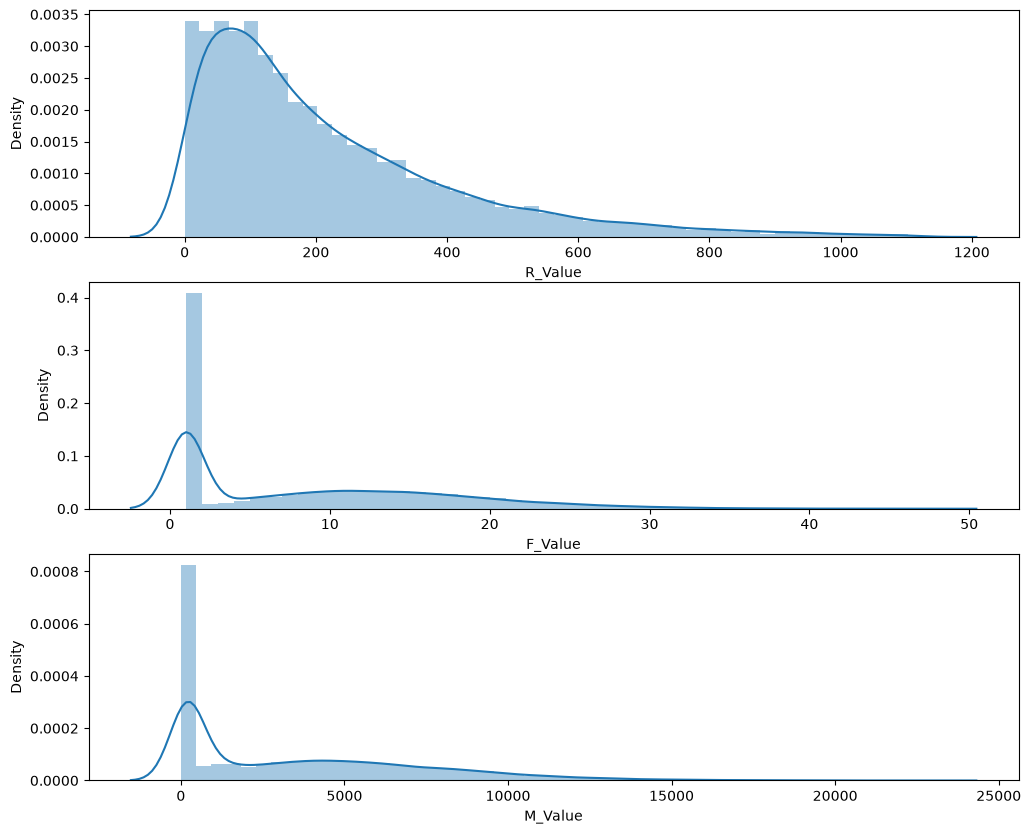

In [30]:
plt.figure(figsize=(12,10)) # Figure size
plt.subplot(3, 1, 1)
sns.distplot(Customer_seg['R_Value'])# Plot distribution of R_Value
plt.subplot(3, 1, 2) 
sns.distplot(Customer_seg['F_Value'])# Plot distribution of F_Value
plt.subplot(3, 1, 3)
sns.distplot(Customer_seg['M_Value'])# Plot distribution of M_Value
plt.show()

In [31]:
quantiles = Customer_seg.quantile(q=[0.25,0.5,0.75]) #Dividing RFM data into four quartiles
quantiles = quantiles.to_dict() 

The total data is divided into 4 quantiles. The R_Value should be low because it indicates recent customer activity and F_value, M_Value should be high since they indicate frequency and total value of purchase. Function is defined to indicate quantiles as numerical values.

In [32]:
# R_Score should be minimum so 1st quantile is set as 1.
def R_Score(a,b,c):
    if a <= c[b][0.25]:
        return 1
    elif a <= c[b][0.50]:
        return 2
    elif a <= c[b][0.75]: 
        return 3
    else:
        return 4
# The higher the F_Score,M_Score the better so 1st quantile is set as 4.    
def FM_Score(x,y,z):
    if x <= z[y][0.25]:
        return 4
    elif x <= z[y][0.50]:
        return 3
    elif x <= z[y][0.75]: 
        return 2
    else:
        return 1

In [33]:
# New column for R_Score to indicate numerical score between 1 to 4.
Customer_seg['R_Score'] = Customer_seg['R_Value'].apply(R_Score, args=('R_Value',quantiles))
# New column for F_Score to indicate numerical score between 1 to 4.
Customer_seg['F_Score'] = Customer_seg['F_Value'].apply(FM_Score, args=('F_Value',quantiles))
# New column for M_Score to indicate numerical score between 1 to 4.
Customer_seg['M_Score'] = Customer_seg['M_Value'].apply(FM_Score, args=('M_Value',quantiles))
Customer_seg.head()

,R_Value,F_Value,M_Value,R_Score,F_Score,M_Score
Order Customer Id,,,,,,
1,792,1,2362.250061,4,4,3
2,136,10,2842.700073,2,2,2
3,229,18,6143.760057,3,1,1
4,380,14,4370.629991,4,2,2
5,457,7,2993.790032,4,3,2


The individual scores of R,F,M are known.A column for combined RFM score is created.

In [34]:
#Adding R,F,M Scores to one new column
Customer_seg['RFM_Score'] = Customer_seg.R_Score.astype(str)+ Customer_seg.F_Score.astype(str) + Customer_seg.M_Score.astype(str)
Customer_seg.head()

,R_Value,F_Value,M_Value,R_Score,F_Score,M_Score,RFM_Score
Order Customer Id,,,,,,,
1,792,1,2362.250061,4,4,3,443
2,136,10,2842.700073,2,2,2,222
3,229,18,6143.760057,3,1,1,311
4,380,14,4370.629991,4,2,2,422
5,457,7,2993.790032,4,3,2,432


How many different customer segments are there in total can be found using .unique() and len method.

In [35]:
count=Customer_seg['RFM_Score'].unique()
print(count)# Printing all Unique values
len(count)# Total count

<StringArray>
['443', '222', '311', '422', '432', '421', '211', '322', '434', '212', '411',
 '331', '412', '433', '321', '423', '333', '312', '221', '223', '332', '233',
 '232', '323', '444', '431', '343', '243', '344', '334', '244', '143', '144']
Length: 33, dtype: str


33

It can be seen that there are 33 different customer segments. To make it easier for segmentation individual R,F,M scores are added together

In [36]:
# Calculate RFM_Score
Customer_seg['RFM_Total_Score'] = Customer_seg[['R_Score','F_Score','M_Score']].sum(axis=1)
Customer_seg['RFM_Total_Score'].unique()

array([11,  6,  5,  8,  9,  7,  4, 10, 12])

There are 9 values in total for customer segmentation.Appropriate names were assigned for each value seperately.

In [37]:
# Define rfm_level function
def RFM_Total_Score(df):

    if (df['RFM_Total_Score'] >= 11):# For RFM score with values 11,12
        return 'Champions' 
    elif (df['RFM_Total_Score'] == 10):# For RFM score with value 10
        return 'Loyal Customers' 
    elif (df['RFM_Total_Score'] == 9): # For RFM score with value 9
        return 'Recent Customers'
    elif (df['RFM_Total_Score'] == 8): # For RFM score with value 8
         return 'Promising'
    elif (df['RFM_Total_Score'] == 7): # For RFM score with value 7
        return 'Customers Needing Attention'
    elif (df['RFM_Total_Score'] == 6): # For RFM score with value 6
        return 'Cant lose them'
    elif (df['RFM_Total_Score'] == 5): # For RFM score with value 5
        return 'At Risk'
    else:                               # For RFM score with value less than 5
        
        return 'Lost'
# Create a new variable RFM_Level
Customer_seg['Customer_Segmentation'] =Customer_seg.apply(RFM_Total_Score, axis=1)
# Print the header with top 5 rows to the console
Customer_seg.head()


,R_Value,F_Value,M_Value,R_Score,F_Score,M_Score,RFM_Score,RFM_Total_Score,Customer_Segmentation
Order Customer Id,,,,,,,,,
1,792,1,2362.250061,4,4,3,443,11,Champions
2,136,10,2842.700073,2,2,2,222,6,Cant lose them
3,229,18,6143.760057,3,1,1,311,5,At Risk
4,380,14,4370.629991,4,2,2,422,8,Promising
5,457,7,2993.790032,4,3,2,432,9,Recent Customers


How many customers are present in each segment?

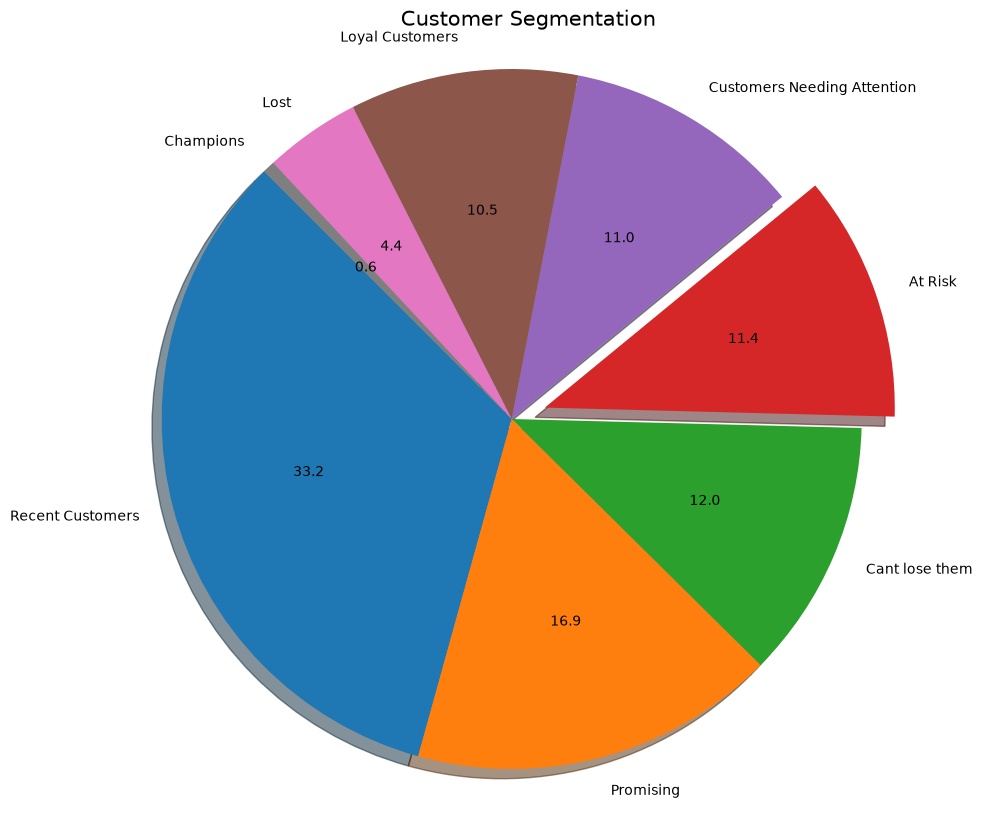

In [38]:
# Calculate average values for each RFM_Level, and return a size of each segment 
Customer_seg['Customer_Segmentation'].value_counts().plot.pie(figsize=(10,10),
                                        startangle=135, explode=(0,0,0,0.1,0,0,0,0),autopct='%.1f',shadow=True)
plt.title("Customer Segmentation",size=15)
plt.ylabel(" ")
plt.axis('equal') 
plt.show()

Since total customers are divided into 9 segments it can be seen that, 11.4% customers are at risk of losing them as customers and 11% customers needs attention else even they will be lost eventually.It can be seen that 4.4% of customers are already lost. 

Our Top 10 Churned best customers who has not purchased anything in a while

In [39]:
churned=Customer_seg[(Customer_seg['RFM_Score']=='411')].sort_values('M_Value', ascending=False).head(10)
churned

,R_Value,F_Value,M_Value,R_Score,F_Score,M_Score,RFM_Score,RFM_Total_Score,Customer_Segmentation
Order Customer Id,,,,,,,,,
11065,309,41,18641.300091,4,1,1,411,6,Cant lose them
6285,332,37,18287.010097,4,1,1,411,6,Cant lose them
7892,392,29,17620.470196,4,1,1,411,6,Cant lose them
2893,312,24,17536.609842,4,1,1,411,6,Cant lose them
4181,425,29,17333.960094,4,1,1,411,6,Cant lose them
4781,502,31,17048.380088,4,1,1,411,6,Cant lose them
9271,344,35,17044.910217,4,1,1,411,6,Cant lose them
4659,417,27,16973.060024,4,1,1,411,6,Cant lose them
1695,326,33,16916.020176,4,1,1,411,6,Cant lose them


These customers used to place orders with huge amounts very frequently but they did not place orders from almost a year which means they are purchasing from other companies. These groups of people should be targeted with offers to gain them back.

Top 10 new best customers who place costly orders often.

In [40]:
#The R_Score should be low and F_Score, M_Score should be as high as possible
Customer_seg[(Customer_seg['RFM_Score']=='144')|(Customer_seg['RFM_Score']=='143')].sort_values('M_Value', ascending=False).head(10)


,R_Value,F_Value,M_Value,R_Score,F_Score,M_Score,RFM_Score,RFM_Total_Score,Customer_Segmentation
Order Customer Id,,,,,,,,,
18047,39,1,1500.0,1,4,3,143,8,Promising
18065,39,1,1500.0,1,4,3,143,8,Promising
18119,38,1,1500.0,1,4,3,143,8,Promising
18101,38,1,1500.0,1,4,3,143,8,Promising
18083,39,1,1500.0,1,4,3,143,8,Promising
18100,38,1,1485.0,1,4,3,143,8,Promising
18064,39,1,1485.0,1,4,3,143,8,Promising
18046,39,1,1485.0,1,4,3,143,8,Promising
18118,38,1,1485.0,1,4,3,143,8,Promising


The above customers has the potential to become best customers this people should be targeted to convert them into loyal customers.All these different segment of customers should be targeted with different tailored advertisments and rewards for increased profits and more responsiveness from customers.

# Data Modelling

To measure the performance of different models the machine learning models are trained to detect fraud,late delivery for classification type. And sales, order quantity is predicted for regression type models.

A new dataset is created with the copy of original data for training the data and validation.

In [41]:
train_data=data.copy()

Two new columns are created for orders with suspected fraud and late delivery making them into binary classification, which in turn helps to measure performance of different models better.

In [42]:
train_data['fraud'] = np.where(train_data['Order Status'] == 'SUSPECTED_FRAUD', 1, 0)
train_data['late_delivery']=np.where(train_data['Delivery Status'] == 'Late delivery', 1, 0)

Now to measure machine models accurately all the columns with repeated values are dropped like late_delivery_risk column because, it is known all the products with late delivery risk are delivered late. And Order Status column because, a new column for fraud detection is created there is a chance machine learning model might take values directly from these columns to predict output.

In [43]:
#Dropping columns with repeated values
train_data.drop(['Delivery Status','Late_delivery_risk','Order Status','order_month_year','order date (DateOrders)'], axis=1, inplace=True)

It is important to check the type of variables in the data because machine learning models can only be trained with numerical values.

In [44]:
train_data.dtypes

Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Id                        int64
Customer Segment                     str
Customer State                       str
Customer Zipcode                 float64
Department Id                      int64
Department Name                      str
Market                               str
Order City                           str
Order Country                        str
Order Customer Id                  int64
Order Id                           int64
Order Item Cardprod Id             int64
Order Item Discount              float64
Order Item Discount Rate         float64
Order Item Id                      int64
Order Item Produ

There are some columns with object type data which cannot be trained in machine learning models so all the object type data is converted to int type using preprocessing label encoder library.

In [45]:
# create the Labelencoder object
le = preprocessing.LabelEncoder()
#convert the categorical columns into numeric
train_data['Customer Country']  = le.fit_transform(train_data['Customer Country'])
train_data['Market']            = le.fit_transform(train_data['Market'])
train_data['Type']              = le.fit_transform(train_data['Type'])
train_data['Product Name']      = le.fit_transform(train_data['Product Name'])
train_data['Customer Segment']  = le.fit_transform(train_data['Customer Segment'])
train_data['Customer State']    = le.fit_transform(train_data['Customer State'])
train_data['Order Region']      = le.fit_transform(train_data['Order Region'])
train_data['Order City']        = le.fit_transform(train_data['Order City'])
train_data['Category Name']     = le.fit_transform(train_data['Category Name'])
train_data['Customer City']     = le.fit_transform(train_data['Customer City'])
train_data['Department Name']   = le.fit_transform(train_data['Department Name'])
train_data['Order State']       = le.fit_transform(train_data['Order State'])
train_data['Shipping Mode']     = le.fit_transform(train_data['Shipping Mode'])
train_data['order_week_day']    = le.fit_transform(train_data['order_week_day'])
train_data['Order Country']     = le.fit_transform(train_data['Order Country'])
train_data['Customer Full Name']= le.fit_transform(train_data['Customer Full Name'])

#display the initial records
train_data.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Category Id,Category Name,Customer City,Customer Country,Customer Id,...,Product Price,Shipping Mode,Customer Full Name,order_year,order_month,order_week_day,order_hour,TotalPrice,fraud,late_delivery
0,1,3,4,91.250000,314.640015,73,40,66,1,20755,...,327.75,3,1875,2018,1,6,22,314.640015,0,0
1,3,5,4,-249.089996,311.359985,73,40,66,1,19492,...,327.75,3,5374,2018,1,2,12,311.359985,0,1
2,0,4,4,-247.779999,309.720001,73,40,452,0,19491,...,327.75,3,4426,2018,1,2,12,309.720001,0,0
3,1,3,4,22.860001,304.809998,73,40,285,0,19490,...,327.75,3,12922,2018,1,2,11,304.809998,0,0
4,2,2,4,134.210007,298.250000,73,40,66,1,19489,...,327.75,3,10632,2018,1,2,11,298.250000,0,0


Now all the data is transformed into int type. The dataset is split into train data and test data so model can be trained with train data and the performance of model can be evaluated using test data.

## Comparision of Classification Models

In [46]:
#All columns expect fraud
xf=train_data.loc[:, train_data.columns != 'fraud']
#Only fraud column
yf=train_data['fraud']
#Splitting the data into two parts in which 80% data will be used for training the model and 20% for testing
xf_train, xf_test,yf_train,yf_test = train_test_split(xf,yf,test_size = 0.2,random_state = 42)
#All columns expect fraud
xl=train_data.loc[:, train_data.columns != 'late_delivery']
#Only fraud column
yl=train_data['late_delivery']
#Splitting the data into two parts in which 80% data will be used for training the model and 20% for testing
xl_train, xl_test,yl_train,yl_test = train_test_split(xl,yl,test_size = 0.2, random_state = 42)

Since there are so many different variables with different ranges standard scaler is used to standardize total the data so it is internally consistent before training the data with machine learning.

In [47]:
sc = StandardScaler()
xf_train=sc.fit_transform(xf_train)
xf_test=sc.transform(xf_test)
xl_train=sc.fit_transform(xl_train)
xl_test=sc.transform(xl_test)

The data is now ready to be used in machine learning models since many different models are compared training every model from begining is complicated so a function is defined to make the process bit easy. The output is in binary classification format so all the models are measured with Accuracy score,recall score and F1 score metrics. 

To measure the performance of different models F1 score is used as the main metric because it is the harmonic mean of precison score and recall score.And all the scores are multiplied with 100 for better understanding

In [ ]:
# Store fresh results from every classification model run.
classification_results = []

def classifiermodel(model_f, model_l, xf_train, xf_test, yf_train, yf_test,
                    xl_train, xl_test, yl_train, yl_test):
    model_f = model_f.fit(xf_train, yf_train)
    model_l = model_l.fit(xl_train, yl_train)

    yf_pred = model_f.predict(xf_test)
    yl_pred = model_l.predict(xl_test)

    accuracy_f = accuracy_score(yf_test, yf_pred)
    accuracy_l = accuracy_score(yl_test, yl_pred)
    precision_f = metrics.precision_score(yf_test, yf_pred, zero_division=0)
    precision_l = metrics.precision_score(yl_test, yl_pred, zero_division=0)
    recall_f = recall_score(yf_test, yf_pred, zero_division=0)
    recall_l = recall_score(yl_test, yl_pred, zero_division=0)
    conf_f = confusion_matrix(yf_test, yf_pred)
    conf_l = confusion_matrix(yl_test, yl_pred)
    f1_f = f1_score(yf_test, yf_pred, zero_division=0)
    f1_l = f1_score(yl_test, yl_pred, zero_division=0)

    model_name = type(model_f).__name__
    classification_results.append({
        'Classification Model': model_name,
        'Fraud Accuracy (%)': accuracy_f * 100,
        'Fraud Precision (%)': precision_f * 100,
        'Fraud Recall (%)': recall_f * 100,
        'Fraud F1 (%)': f1_f * 100,
        'Late Delivery Accuracy (%)': accuracy_l * 100,
        'Late Delivery Precision (%)': precision_l * 100,
        'Late Delivery Recall (%)': recall_l * 100,
        'Late Delivery F1 (%)': f1_l * 100
    })

    print('Model parameters used are:', model_f)
    print('Fraud detection - Accuracy:', accuracy_f * 100, '%')
    print('Fraud detection - Precision:', precision_f * 100, '%')
    print('Fraud detection - Recall:', recall_f * 100, '%')
    print('Fraud detection - F1 score:', f1_f * 100, '%')
    print('Fraud confusion matrix:\\n', conf_f)
    print('Late delivery - Accuracy:', accuracy_l * 100, '%')
    print('Late delivery - Precision:', precision_l * 100, '%')
    print('Late delivery - Recall:', recall_l * 100, '%')
    print('Late delivery - F1 score:', f1_l * 100, '%')
    print('Late delivery confusion matrix:\\n', conf_l)

    return classification_results[-1]

### Logistic classification model

In [ ]:
model_f = LogisticRegression(solver='lbfgs',random_state=0) #the classification model
model_l = LogisticRegression(solver='lbfgs',random_state=0) #the classification model
#Giving inputs to the defined function
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Gaussian naive bayes model

In [ ]:
model_f = GaussianNB()
model_l = GaussianNB()
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Support vector machines

In [ ]:
model_f = svm.LinearSVC()
model_l = svm.LinearSVC()
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### K nearest Neighbors classification

In [ ]:
model_f = KNeighborsClassifier(n_neighbors=1)
model_l = KNeighborsClassifier(n_neighbors=1)
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Linear Discriminant Analysis

In [ ]:
model_f = LinearDiscriminantAnalysis()
model_l = LinearDiscriminantAnalysis()
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Random forest classification

In [ ]:
model_f = RandomForestClassifier()
model_l = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0)
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Extra trees classification

In [ ]:
model_f = ExtraTreesClassifier(n_estimators=100, max_depth=None,random_state=0)
model_l = ExtraTreesClassifier(n_estimators=100, max_depth=None,random_state=0)
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### eXtreme Gradient Boosting Classification

In [56]:
import pandas as pd
import xgboost as xgb
import sys

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Pandas location:", pd.__file__)
print("Has pandas.util:", hasattr(pd, "util"))
print("XGBoost:", xgb.__version__)

Python: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.1.1
Pandas location: C:\Users\Admin\AppData\Roaming\Python\Python314\site-packages\pandas\__init__.py
Has pandas.util: True
XGBoost: 3.4.1


In [ ]:
model_f = xgb.XGBClassifier()
model_l = xgb.XGBClassifier()
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Decision tree classification

In [ ]:
model_f = tree.DecisionTreeClassifier()
model_l = tree.DecisionTreeClassifier()
classifiermodel(model_f,model_l,xf_train, xf_test,yf_train,yf_test,xl_train, xl_test,yl_train,yl_test)

### Comparison of Classification Models

**Important:** The classification function above has been corrected so recall is now calculated with the true labels first and the predicted labels second. The values in the old comparison table must therefore be refreshed. Run the classification model cells above (Logistic Regression through Decision Tree), then update the table below using the newly printed results. Do not submit the old recall values.

In [ ]:
# Compare the classification models using the results collected above.
# Run all classification model cells (Logistic Regression through Decision Tree) first.
classification_comparision = pd.DataFrame(classification_results)
display(classification_comparision)

### Comparision Table for Classification Scores

In [60]:
classification_comparision #Printing dataframe

,Classification Model,Accuracy Score for Fraud Detection,Recall Score for Fraud Detection,F1 Score for Fraud Detection,Accuracy Score for Late Delivery,Recall Score for Late Delivery,F1 Score for Late Delivery
0,Logistic,97.80,59.40,31.22,98.84,97.94,98.96
1,Gausian Naive bayes,87.84,16.23,27.92,57.27,56.20,71.95
2,Support Vector Machines,97.75,56.89,28.42,98.84,97.94,98.96
3,K nearest Neighbour,97.36,41.90,35.67,80.82,83.45,82.26
4,Linear Discriminant Analysis,97.88,56.57,49.20,98.37,97.68,98.52
5,Random Forest,98.48,93.18,54.57,98.60,97.52,98.74
6,Extra trees,98.61,98.88,58.60,99.17,98.51,99.25
7,eExtreme gradient boosting,98.93,89.89,73.22,99.24,98.65,99.31
8,Decision tree,99.12,82.53,81.00,99.37,99.44,99.42


In [61]:
classification_comparision.max() #Checking max values in every column

Classification Model                  eExtreme gradient boosting
Accuracy Score for Fraud Detection                         99.12
Recall Score for Fraud Detection                           98.88
F1 Score for Fraud Detection                                81.0
Accuracy Score for Late Delivery                           99.37
Recall Score for Late Delivery                             99.44
F1 Score for Late Delivery                                 99.42
dtype: object

[[](http://)](http://)Considering F1 score it is clear that Decision Tree classifier is performing better for classification type with F1 score of almost 80% for fraud detection and 99.42% for late delivery.Suprisingly, all the models expect gussian model predicted the late delivery of orders with almost 98% accuracy.Just to make sure that model is predicting correctly the model is cross validated and the results are compared with accuracy of the model.

### Cross validation

In [62]:
#Defining cross validation model
def cross_validation_model(model_f,model_l,xf,yf,xl,yl):
    model_f= model_f.fit(xf,yf)
    model_l = model_l.fit(xl,yl)
    scores_f = cross_val_score(model_f, xf, yf, cv=6)
    scores_l = cross_val_score(model_l, xl, yl, cv=6)
    print('Model used is',model_f)
    print('Cross validation accuracy of fraud: %0.2f (+/- %0.2f)' % (scores_f.mean(), scores_f.std() * 2))
    print('Cross validation accuracy of late : %0.2f (+/- %0.2f)' % (scores_l.mean(), scores_l.std() * 2))

In [63]:
cross_validation_model(model_f,model_l,xf,yf,xl,yl)

Model used is DecisionTreeClassifier()
Cross validation accuracy of fraud: 0.96 (+/- 0.04)
Cross validation accuracy of late : 0.98 (+/- 0.02)


Since, the difference between cross validated scores and accuracy scores of the model is very minimal it can be confirmed that the data is neither overfitted or underfitted, Which variable was given more importance in the model is found using feature importance method from sklearn.

### Feature Importance

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43],
 [Text(0, 0, 'Days for shipping (real)'),
  Text(1, 0, 'late_delivery'),
  Text(2, 0, 'Customer Full Name'),
  Text(3, 0, 'Type'),
  Text(4, 0, 'Order State'),
  Text(5, 0, 'Shipping Mode'),
  Text(6, 0, 'order_hour'),
  Text(7, 0, 'Order Id'),
  Text(8, 0, 'Order City'),
  Text(9, 0, 'Order Customer Id'),
  Text(10, 0, 'Customer City'),
  Text(11, 0, 'Customer Id'),
  Text(12, 0, 'Customer Zipcode'),
  Text(13, 0, 'order_week_day'),
  Text(14, 0, 'Order Country'),
  Text(15, 0, 'order_month'),
  Text(16, 0, 'Order Item Id'),
  Text(17, 0, 'Customer State'),
  Text(18, 0, 'Order Region'),
  Text(19, 0, 'Days for shipment (scheduled)'),
  Text(20, 0, 'Customer Segment'),
  Text(21, 0, 'Market'),
  Text(22, 0, 'Order Item Profit Ratio'),

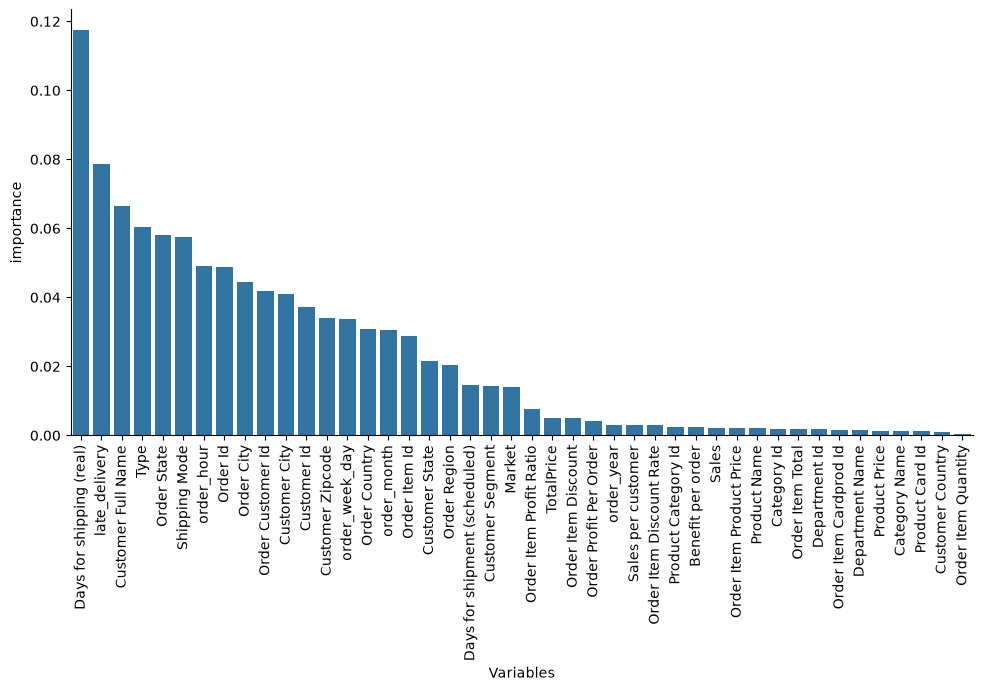

In [64]:
important_col=model_f.feature_importances_.argsort()
feat_imp=pd.DataFrame({'Variables':xf.columns[important_col],'importance':model_f.feature_importances_[important_col]})
feat_imp=feat_imp.sort_values(by='importance',ascending=False)
ax = sns.catplot(x='Variables', y = 'importance', data=feat_imp, height=5, aspect=2,  kind="bar")
plt.xticks(rotation=90)

Even though fraud detection is not at all related to Days for shipping(real) it is very surprising to see it was given an importance of 0.12. All other important parameters like customer full name, shipping mode, type of payment used are given an importance of 0.7 which helps the company to detect fraud accurately when same customer is conducting fraud.

Same way which variables were given importance for prediction of late delivery is found.

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43],
 [Text(0, 0, 'Days for shipping (real)'),
  Text(1, 0, 'Days for shipment (scheduled)'),
  Text(2, 0, 'fraud'),
  Text(3, 0, 'Customer Full Name'),
  Text(4, 0, 'Order City'),
  Text(5, 0, 'Order State'),
  Text(6, 0, 'Type'),
  Text(7, 0, 'Order Country'),
  Text(8, 0, 'Order Customer Id'),
  Text(9, 0, 'order_hour'),
  Text(10, 0, 'Order Id'),
  Text(11, 0, 'Customer Zipcode'),
  Text(12, 0, 'Order Item Id'),
  Text(13, 0, 'Customer City'),
  Text(14, 0, 'Customer Id'),
  Text(15, 0, 'Customer State'),
  Text(16, 0, 'order_week_day'),
  Text(17, 0, 'order_month'),
  Text(18, 0, 'Order Region'),
  Text(19, 0, 'Customer Segment'),
  Text(20, 0, 'Order Item Discount'),
  Text(21, 0, 'Market'),
  Text(22, 0, 'Benefit per order'),
  Text(

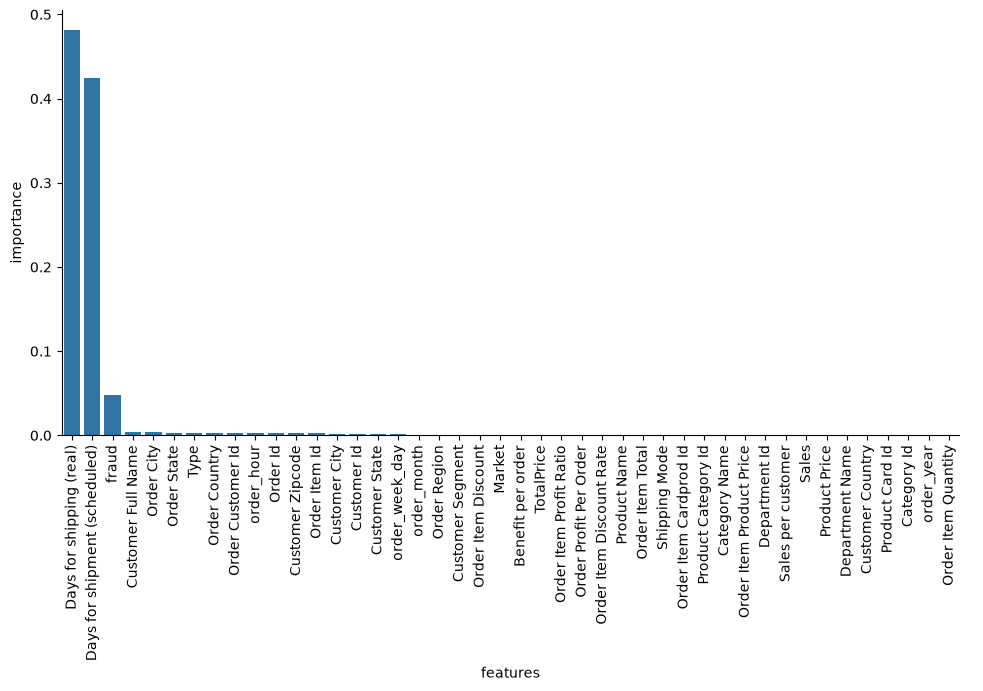

In [65]:
important_col=model_l.feature_importances_.argsort()
feat_imp=pd.DataFrame({'features':xl.columns[important_col],'importance':model_l.feature_importances_[important_col]})
feat_imp=feat_imp.sort_values(by='importance',ascending=False)
ax = sns.catplot(x='features', y = 'importance', data=feat_imp, height=5, aspect=2,  kind="bar")
plt.xticks(rotation=90)

It can be seen that the columns for the days of shipping is given almost 90% importance in decision tree model,it will be interesting to see how well the model can predict when these variables are removed.

So a new model with the copy of train data is created
.

In [66]:
new_data=train_data.copy()

In [67]:
# Dropping columns in new data set
new_data=new_data.drop(['Days for shipping (real)','Days for shipment (scheduled)'],axis=1)

In [68]:
#All columns expect fraud
new_xl=new_data.loc[:, new_data.columns != 'late_delivery']
#Only fraud column
new_yl=train_data['late_delivery']
#Splitting the data into two parts in which 80% data will be used for training the model and 20% for testing
new_xl_train, new_xl_test,new_yl_train,new_yl_test = train_test_split(new_xl,new_yl,test_size = 0.2,random_state = 42)

Standardizing data with Standardscaler module:

In [69]:
new_xl_train=sc.fit_transform(new_xl_train)
new_xl_test=sc.transform(new_xl_test)

Function for classification model is created to train one model

In [ ]:
def New_classifiermodel(model_c,xc_train, xc_test,yc_train,yc_test):
    model_c = model_c.fit(xc_train, yc_train)
    yc_pred = model_c.predict(xc_test)
    accuracy_c = accuracy_score(yc_test, yc_pred)
    recall_c = recall_score(yc_test, yc_pred, average='weighted', zero_division=0)
    conf_c = confusion_matrix(yc_test, yc_pred)
    f1_c = f1_score(yc_test, yc_pred, average='weighted', zero_division=0)
    print('Model parameters used are:', model_c)
    print('Accuracy:', accuracy_c * 100, '%')
    print('Recall score:', recall_c * 100, '%')
    print('Confusion matrix:\\n', conf_c)
    print('F1 score:', f1_c * 100, '%')
    return {'accuracy': accuracy_c, 'recall': recall_c, 'f1': f1_c, 'confusion_matrix': conf_c}

### Decision Tree classification

In [ ]:
new_model_l=tree.DecisionTreeClassifier()
New_classifiermodel(new_model_l,new_xl_train, new_xl_test,new_yl_train,new_yl_test)

Even when shipping days variables were removed the F1 score and the accuracy of the new model is nearly 84% which is still pretty good. Which variables are given more importance this time?

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41],
 [Text(0, 0, 'Shipping Mode'),
  Text(1, 0, 'order_hour'),
  Text(2, 0, 'Customer Full Name'),
  Text(3, 0, 'Order City'),
  Text(4, 0, 'Order State'),
  Text(5, 0, 'Order Customer Id'),
  Text(6, 0, 'Customer City'),
  Text(7, 0, 'Customer Id'),
  Text(8, 0, 'Order Id'),
  Text(9, 0, 'Customer Zipcode'),
  Text(10, 0, 'Order Item Id'),
  Text(11, 0, 'fraud'),
  Text(12, 0, 'Order Country'),
  Text(13, 0, 'order_week_day'),
  Text(14, 0, 'order_month'),
  Text(15, 0, 'Customer State'),
  Text(16, 0, 'Order Region'),
  Text(17, 0, 'Order Item Discount'),
  Text(18, 0, 'TotalPrice'),
  Text(19, 0, 'Order Item Profit Ratio'),
  Text(20, 0, 'Benefit per order'),
  Text(21, 0, 'Type'),
  Text(22, 0, 'Customer Segment'),
  Text(23, 0, 'Order Profit Per 

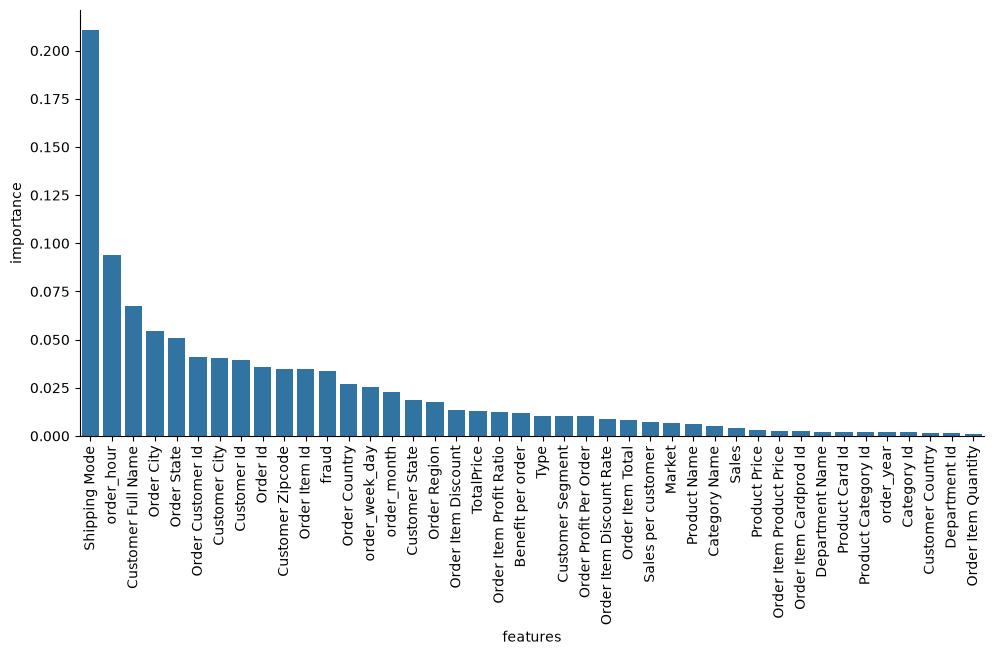

In [72]:
important_col=new_model_l.feature_importances_.argsort()
feat_imp=pd.DataFrame({'features':new_xl.columns[important_col],'importance':new_model_l.feature_importances_[important_col]})
feat_imp=feat_imp.sort_values(by='importance',ascending=False)
ax = sns.catplot(x='features', y = 'importance', data=feat_imp, height=5, aspect=2,  kind="bar")
plt.xticks(rotation=90)

This time variables like shipping mode, order city,state are given more importance which helps company to use different shipping methods to deliver products faster.

Since Decision Tree classfier performed better for binary classification it will be interesting to see how well the model performs for multiclassification type data. So model was trained to predict order country.

In [73]:
#All columns expect order country
xc=train_data.loc[:, train_data.columns != 'Order Country']
#Order column country
yc=train_data['Order Country']
#Splitting 20% of dataset as test data 
xc_train, xc_test,yc_train,yc_test = train_test_split(xc,yc,test_size = 0.2, random_state = 42)

In [74]:
xc_train=sc.fit_transform(xc_train)
xc_test=sc.transform(xc_test)

### Decision Tree Multi Classification Model

In [ ]:
model_c=tree.DecisionTreeClassifier()
New_classifiermodel(model_c,xc_train, xc_test,yc_train,yc_test)

Wow! It is really suprising to see F1 score of almost 100% to predict order country. So it can be concluded that the Decision Tree classifier works best for this dataset for classification type.

Decision Tree classifier is identified as the best model in all Machine learning models for Classification Type data. How well it can perform when compared with Neural Network model?

### Neural Network Model for Classification

In [85]:
keras.layers.BatchNormalization()
classifier = Sequential()
#First Hidden Layer
classifier.add(Dense(1024, activation='relu',kernel_initializer='random_normal', input_dim=44)) #Since we have 44 columns
#Third Hidden Layer
classifier.add(Dense(512, activation='relu',kernel_initializer='random_normal'))
#Fourth Hidden Layer
classifier.add(Dense(256, activation='relu',kernel_initializer='random_normal'))
#Fifth Hidden Layer
classifier.add(Dense(128, activation='relu',kernel_initializer='random_normal'))
#Sixth Hidden Layer
classifier.add(Dense(64, activation='relu',kernel_initializer='random_normal'))
#Seventh Hidden Layer
classifier.add(Dense(32, activation='relu',kernel_initializer='random_normal'))
#Eight Hidden Layer
classifier.add(Dense(16, activation='relu',kernel_initializer='random_normal'))
#Ninth Hidden Layer
classifier.add(Dense(8, activation='relu',kernel_initializer='random_normal'))
#Tenth Hidden Layer
classifier.add(Dense(4, activation='relu',kernel_initializer='random_normal'))
#Eleventh Hidden Layer
classifier.add(Dense(2, activation='relu',kernel_initializer='random_normal'))
#Output Layer
classifier.add(Dense(1, activation='sigmoid',kernel_initializer='random_normal'))

Since output data is binary classification the binary_crossentropy is used to measure loss and accuracy is used as metric to train the model because F1 score is not available in Keras.

In [86]:
classifier.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

The model is trained with batch size of 512 and 10 epochs.

In [87]:
print("Training data shape:", xf_train.shape)
print("Fraud labels shape:", yf_train.shape)

print("Neural network input shape:", classifier.input_shape)

Training data shape: (144415, 44)
Fraud labels shape: (144415,)
Neural network input shape: (None, 44)


In [88]:
#Fitting the data to the training dataset
classifier.fit(xf_train,yf_train, batch_size=512, epochs=10)

Epoch 1/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.9778 - loss: 0.2388
Epoch 2/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 16s 56ms/step - accuracy: 0.9778 - loss: 0.0542
Epoch 3/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.9778 - loss: 0.0512
Epoch 4/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.9778 - loss: 0.0493
Epoch 5/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.9778 - loss: 0.0480
Epoch 6/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 17s 60ms/step - accuracy: 0.9778 - loss: 0.0467
Epoch 7/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 17s 61ms/step - accuracy: 0.9778 - loss: 0.0450
Epoch 8/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.9778 - loss: 0.0436
Epoch 9/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 21s 74ms/step - accuracy: 0.9778 - loss: 0.0415
Epoch 10/10
283/283 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.9778 - loss: 0.0393


It can be seen that the neural network model is performing better with every epoch even tough accuracy remained same the loss is decreasing with every epoch.Since every cell results is saved in jupyter notebook for the next iteration the model is trained with 30 more epochs and the results are displayed.

In [89]:
classifier.fit(xf_train,yf_train, batch_size=512, epochs=30)

Epoch 1/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 19s 66ms/step - accuracy: 0.9778 - loss: 0.0363
Epoch 2/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - accuracy: 0.9822 - loss: 0.0343
Epoch 3/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 27s 96ms/step - accuracy: 0.9833 - loss: 0.0333
Epoch 4/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 31s 62ms/step - accuracy: 0.9853 - loss: 0.0305
Epoch 5/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.9861 - loss: 0.0286
Epoch 6/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 28s 100ms/step - accuracy: 0.9873 - loss: 0.0269
Epoch 7/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 29s 102ms/step - accuracy: 0.9882 - loss: 0.0256
Epoch 8/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.9879 - loss: 0.0254
Epoch 9/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 24s 86ms/step - accuracy: 0.9885 - loss: 0.0247
Epoch 10/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 25s 89ms/step - accuracy: 0.9895 - loss: 0.0231
Epoch 11/30
283/283 ━━━━━━━━━━━━━━━━━━━━ 25s 88ms/step - accuracy: 0.9900 - loss: 0.0221
Epoch 12/30
283/283 ━━━━━━━━

The model is evaluated with test data set

In [ ]:
train_evaluate = classifier.evaluate(xf_train, yf_train, verbose=0)
test_evaluate = classifier.evaluate(xf_test, yf_test, verbose=0)
print('Evaluation for training set:', train_evaluate)
print('Evaluation for test set:', test_evaluate)

# The network has one sigmoid output, so convert probabilities to class labels
# using a 0.5 threshold. Do not use argmax for a single sigmoid output.
yf_pred1 = classifier.predict(xf_test, batch_size=512, verbose=1)
yf_pred = (yf_pred1 >= 0.5).astype(int).ravel()

print('Fraud F1 Score:', f1_score(yf_test, yf_pred, zero_division=0))
print('Confusion Matrix:')
print(confusion_matrix(yf_test, yf_pred))

The neural network uses a single sigmoid output for binary fraud classification. Its predicted probabilities are converted into class labels using a threshold of 0.5, and its F1 score is calculated from those labels. The corrected score should be compared with the machine-learning classifiers after this cell is rerun. The previous score produced using argmax was not a valid evaluation for a single sigmoid output.

Understand hyperparameter tuning
Hyperparameters are settings we choose before training a model.

For example, in a Decision Tree:
- max_depth: Controls how deep the tree can grow.
- min_samples_split: Controls the minimum samples needed to split a node.
- min_samples_leaf: Controls the minimum samples allowed in a leaf.
We want to find the settings that give the best prediction
 Add GridSearchCV

In [91]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Create the model
dt = DecisionTreeClassifier(random_state=42)

# Choose hyperparameters to test
param_grid = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

# Perform Grid Search
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(xf_train, yf_train)

print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Fitting 3 folds for each of 90 candidates, totalling 270 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best F1 Score: 0.6958304022039398


Add RandomizedSearchCV

In [92]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'criterion': ['gini', 'entropy']
}

random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(xf_train, yf_train)

print("Best Parameters:", random_search.best_params_)
print("Best F1 Score:", random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 9}
Best F1 Score: 0.6139674323069367


Evaluate your tuned models

In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

best_grid_model = grid_search.best_estimator_
best_random_model = random_search.best_estimator_

for name, model in [
    ("GridSearchCV", best_grid_model),
    ("RandomizedSearchCV", best_random_model)
]:
    predictions = model.predict(xf_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(yf_test, predictions))
    print("Precision:", precision_score(yf_test, predictions, zero_division=0))
    print("Recall:", recall_score(yf_test, predictions, zero_division=0))
    print("F1 Score:", f1_score(yf_test, predictions, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(yf_test, predictions))


 GridSearchCV
Accuracy: 0.9921615333481054
Precision: 0.8436363636363636
Recall: 0.8188235294117647
F1 Score: 0.831044776119403
Confusion Matrix:
[[35125   129]
 [  154   696]]

 RandomizedSearchCV
Accuracy: 0.9878406824728562
Precision: 0.7693315858453473
Recall: 0.6905882352941176
F1 Score: 0.7278363298202107
Confusion Matrix:
[[35078   176]
 [  263   587]]


 Comparison of GridSearchCV and RandomizedSearchCV

The performance of GridSearchCV and RandomizedSearchCV was evaluated using a test dataset. The results showed that GridSearchCV achieved an accuracy of 99.22%, precision of 84.36%, recall of 81.88%, and F1 score of 83.10%.

RandomizedSearchCV achieved an accuracy of 98.78%, precision of 76.93%, recall of 69.06%, and F1 score of 72.78%.

GridSearchCV performed better across all evaluation metrics. It also correctly identified more fraudulent transactions, detecting 696 compared with 587 for RandomizedSearchCV.

Therefore, GridSearchCV was the better-performing tuning method in this experiment. However, this result applies to the selected dataset and search spaces and does not mean GridSearchCV will always outperform RandomizedSearchCV.

## Comparision of Regression Models

For comparison of regression models sales and order quantity are predicted

In [94]:
xs=train_data.loc[:, train_data.columns != 'Sales']
ys=train_data['Sales']
xs_train, xs_test,ys_train,ys_test = train_test_split(xs,ys,test_size = 0.3, random_state = 42)
xq=train_data.loc[:, train_data.columns != 'Order Item Quantity']
yq=train_data['Order Item Quantity']
xq_train, xq_test,yq_train,yq_test = train_test_split(xq,yq,test_size = 0.3, random_state = 42)


MinMax scaler is used to standardize data since data type is regression.

In [95]:
scaler=MinMaxScaler()
xs_train=scaler.fit_transform(xs_train)
xs_test=scaler.transform(xs_test)
xq_train=scaler.fit_transform(xq_train)
xq_test=scaler.transform(xq_test)

The data is now ready to be used in machine learning models.Since, different models are compared here like above a function is defined. The output is regression type so accuracy cannot be used as a measure to compare different models like classification models, so all the models are compared using mean absolute error (MAE) and RMSE.

The lower the value of mean absolute error the better the model is performing and lower values of RMSE indicate better fit.

In [ ]:
# Store regression results so the comparison table is generated from actual test predictions.
regression_results = []

def regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test):
    model_s = model_s.fit(xs_train, ys_train)
    model_q = model_q.fit(xq_train, yq_train)
    ys_pred = model_s.predict(xs_test)
    yq_pred = model_q.predict(xq_test)

    sales_mae = metrics.mean_absolute_error(ys_test, ys_pred)
    sales_rmse = np.sqrt(metrics.mean_squared_error(ys_test, ys_pred))
    quantity_mae = metrics.mean_absolute_error(yq_test, yq_pred)
    quantity_rmse = np.sqrt(metrics.mean_squared_error(yq_test, yq_pred))

    regression_results.append({
        'Regression Model': type(model_s).__name__,
        'MAE Value for Sales': sales_mae,
        'RMSE Value for Sales': sales_rmse,
        'MAE Value for Quantity': quantity_mae,
        'RMSE Value for Quantity': quantity_rmse
    })

    print('Model parameters used are:', model_s)
    print('MAE of sales:', sales_mae)
    print('RMSE of sales:', sales_rmse)
    print('MAE of order quantity:', quantity_mae)
    print('RMSE of order quantity:', quantity_rmse)
    return regression_results[-1]

### Lasso Regression

In [ ]:
model_s = linear_model.Lasso(alpha=0.1)
model_q = linear_model.Lasso(alpha=0.1)
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### Ridge Regression

In [ ]:
model_s = Ridge(alpha=1.0)
model_q = Ridge(alpha=1.0)
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### Light Gradient Boosting Regression

In [ ]:
model_s = lgb.LGBMRegressor()
model_q = lgb.LGBMRegressor()
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### Random Forest Regression

In [ ]:
model_s = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=40)
model_q = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=40)
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### eXtreme Gradient Boosting Regression

In [ ]:
model_s = xgb.XGBRegressor()
model_q = xgb.XGBRegressor()
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### Decision Tree Regression

In [ ]:
model_s = tree.DecisionTreeRegressor()
model_q = tree.DecisionTreeRegressor()
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

### Linear Regression

In [ ]:
model_s=LinearRegression()
model_q=LinearRegression()
regressionmodel(model_s,model_q,xs_train, xs_test,ys_train,ys_test,xq_train, xq_test,yq_train,yq_test)

For better understanding and comparision of all the scores a dataframe is created

In [ ]:
# Compare regression models using the actual test-set predictions collected above.
Regression_comparision = pd.DataFrame(regression_results)
display(Regression_comparision)

### Comparision Table for Regression Model Scores

In [105]:
Regression_comparision #Printing dataframe

,Regression Model,MAE Value for Sales,RMSE Value for Sales,MAE Value for Quantity,RMSE Value for Quantity
0,Lasso,1.5500,2.3300,0.9000,1.030
1,Ridge,0.7500,0.9700,0.3400,0.520
2,Light Gradient Boosting,0.4600,1.6600,0.0010,0.011
3,Random Forest,0.1900,1.7900,0.0001,0.006
4,eXtreme gradient boosting,0.1540,3.1300,0.0005,0.004
5,Decision tree,0.0130,0.9180,3.6900,0.006
6,Linear Regression,0.0005,0.0014,0.3400,0.520


The MAE and RMSE values should be as low as possible. The following cell displays the minimum value for each metric. The best model can differ depending on whether we are predicting Sales or Order Item Quantity.

In [ ]:
# Identify the model with the lowest error for each target and metric.
numeric_errors = Regression_comparision.select_dtypes(include='number')
print('Lowest error for each metric:')
display(numeric_errors.min())

print('Best model for each metric (lower is better):')
for metric_name in numeric_errors.columns:
    best_index = numeric_errors[metric_name].idxmin()
    print(f'{metric_name}: {Regression_comparision.loc[best_index, "Regression Model"]}')

The regression comparison table is generated from the models' actual predictions on the test data. Lower MAE and RMSE values indicate smaller prediction errors. The best model may differ between Sales and Order Item Quantity, so the minimum-error summary above identifies the strongest model separately for each metric. Compare these results with the neural-network regression evaluation below before making a final selection.

### Neural Network Model for Regression

In [107]:
regressor = Sequential()

#First Hidden Layer
regressor.add(Dense(512, activation='relu',kernel_initializer='normal',input_dim=44))
#Second  Hidden Layer
regressor.add(Dense(256, activation='relu',kernel_initializer='normal'))
#Third  Hidden Layer
regressor.add(Dense(256, activation='relu',kernel_initializer='normal'))
#Fourth  Hidden Layer
regressor.add(Dense(256, activation='relu',kernel_initializer='normal'))
#Fifth  Hidden Layer
regressor.add(Dense(256, activation='relu',kernel_initializer='normal'))

#Output Layer
regressor.add(Dense(1, activation='linear'))# Linear activation is used.

The mean absolute error is used as loss metric to train the model.

In [108]:
regressor.compile(optimizer='adam',loss='mean_absolute_error',metrics=['mean_absolute_error'])

In [109]:
#Fitting the data to the training dataset
regressor.fit(xq_train,yq_train, batch_size=256, epochs=10)

Epoch 1/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 0.2547 - mean_absolute_error: 0.2547
Epoch 2/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 0.0887 - mean_absolute_error: 0.0887
Epoch 3/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.0672 - mean_absolute_error: 0.0672
Epoch 4/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.0578 - mean_absolute_error: 0.0578
Epoch 5/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - loss: 0.0542 - mean_absolute_error: 0.0542
Epoch 6/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 0.0407 - mean_absolute_error: 0.0407
Epoch 7/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.0339 - mean_absolute_error: 0.0339
Epoch 8/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - loss: 0.0339 - mean_absolute_error: 0.0339
Epoch 9/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - loss: 0.0323 - mean_absolute_error: 0.0323
Epoch 10/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - loss: 0.0292 - mean_absolute_error: 0.0292


The model is performing better with every epoch so the model is trained again with 50 more epochs

In [110]:
regressor.fit(xq_train,yq_train, batch_size=256, epochs=50)

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0334 - mean_absolute_error: 0.0334
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.0284 - mean_absolute_error: 0.0284
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - loss: 0.0272 - mean_absolute_error: 0.0272
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - loss: 0.0239 - mean_absolute_error: 0.0239
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 0.0226 - mean_absolute_error: 0.0226
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 0.0201 - mean_absolute_error: 0.0201
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 0.0225 - mean_absolute_error: 0.0225
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - loss: 0.0234 - mean_absolute_error: 0.0234
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 0.0224 - mean_absolute_error: 0.0224
Epoch 10/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - loss: 0.0206 - mean_absolute_error: 0.0206
Epoch 11/

It can be observed that the  mean absolute error is reducing with every epoch.So it trained again with 10 more epochs to see if model can perform any better.

In [111]:
#Fitting the data to the training dataset
regressor.fit(xq_train,yq_train, batch_size=256, epochs=10)

Epoch 1/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 0.0089 - mean_absolute_error: 0.0089
Epoch 2/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.0081 - mean_absolute_error: 0.0081
Epoch 3/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.0084 - mean_absolute_error: 0.0084
Epoch 4/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0087 - mean_absolute_error: 0.0087
Epoch 5/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.0080 - mean_absolute_error: 0.0080
Epoch 6/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0080 - mean_absolute_error: 0.0080
Epoch 7/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 0.0082 - mean_absolute_error: 0.0082
Epoch 8/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0075 - mean_absolute_error: 0.0075
Epoch 9/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0081 - mean_absolute_error: 0.0081
Epoch 10/10
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.0077 - mean_absolute_error: 0.0077


The loss and MAE values started to increase so the training is stopped. The best MAE value observed is 0.0074. 

The test data is evaluated to find the MAE, RMSE values.

In [112]:
pred_train_q= regressor.predict(xq_train)
pred_q_test= regressor.predict(xq_test)
print('MAE Value train data:',regressor.evaluate(xq_train,yq_train))
print('RMSE of train data:',np.sqrt(mean_squared_error(yq_train,pred_train_q)))
print('MAE Value test data:',regressor.evaluate(xq_test,yq_test))
print('RMSE of test data:',np.sqrt(mean_squared_error(yq_test,pred_q_test)))

3949/3949 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step
3949/3949 ━━━━━━━━━━━━━━━━━━━━ 22s 5ms/step - loss: 0.0088 - mean_absolute_error: 0.0088
MAE Value train data: [0.008807935751974583, 0.008807935751974583]
RMSE of train data: 0.015578783684775856
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0087 - mean_absolute_error: 0.0087
MAE Value test data: [0.008725269697606564, 0.008725269697606564]
RMSE of test data: 0.015393088130496953


The neural-network regression model is evaluated on the test set using MAE and RMSE. Compare these values with the traditional regression models in the table above. The model with the lowest test error is the strongest performer for that target in this experiment.

# Conclusion

# Conclusion

This practical assignment applied Machine Learning evaluation metrics and hyperparameter tuning to the DataCo Supply Chain dataset. Classification and regression models were trained and evaluated using separate training and test data.

For classification, the models were compared using accuracy, precision, recall, F1-score, and confusion matrices. These metrics provide different views of model performance. Accuracy measures the overall proportion of correct predictions, while precision, recall, and F1-score provide additional information about positive-class predictions. The corrected classification functions calculate metrics using the true labels first and predicted labels second. The comparison table is generated from the actual model runs.

For regression, the models were compared using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) for Sales and Order Item Quantity. Lower values indicate better predictive performance. The comparison table is generated directly from the test predictions, and the minimum-error summary identifies the best model separately for each target and metric.

Hyperparameter tuning was performed using GridSearchCV and RandomizedSearchCV with a Decision Tree classifier. GridSearchCV evaluates all combinations in the specified parameter grid, while RandomizedSearchCV evaluates a selected number of sampled combinations. Their cross-validation and held-out test results are used to compare the tuned models. The best model should be selected using the evaluation metrics most appropriate to the problem, rather than accuracy alone.

Overall, the practical demonstrates how evaluation metrics support fair model comparison and how hyperparameter tuning can improve model configuration. The conclusions should be based on the refreshed results produced when the notebook is run with the dataset.

## Final submission checklist

The lecturer's stated task focuses on Machine Learning evaluation metrics, hyperparameter tuning, model comparison, and justification of model selection. It does not specify an RNN, so an RNN is not required for this brief.

Before submitting:
1. Keep `DataCoSupplyChainDataset.csv` in the same folder as this notebook, or update the file path in the data-loading cell.
2. Restart the notebook kernel and run all cells from top to bottom.
3. Confirm that the classification comparison table contains fresh results for every classifier.
4. Confirm that the regression comparison table is populated from the model runs.
5. Check that GridSearchCV and RandomizedSearchCV both complete and display their best parameters, cross-validation scores, and test-set metrics.
6. Save the notebook after the outputs have refreshed.

If a cell reports a missing package, install that package in the same Python environment used by Jupyter, then restart and run all cells again.